# APRAU 2026/27 — Grupo 18
## Projeto de Machine Learning — Dataset Clínico Cardiometabólico

Sections:
1. Setup & Data Loading
2. Exploratory Data Analysis (EDA)
3. Regression — `target_regression`
4. Classification — `target_class`
5. Feature Selection (Ridge & Lasso)

## 1. Setup & Data Loading

In [2]:
# Run this cell only on Google Colab
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    DATASET_PATH = '../dataset_grupo_18.csv'

**O que faz:** Detecta se o notebook está a correr no Google Colab ou localmente e define o caminho para o ficheiro CSV em conformidade.

 O Colab monta o Google Drive e os ficheiros ficam num caminho diferente do repositório local. Separar esta lógica no início evita erros de path nas células seguintes e torna o notebook portátil sem alterações manuais.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split, cross_val_score,
    LeaveOneOut, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils import resample

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

**O que faz:** Importa todas as bibliotecas necessárias para as cinco secções do notebook num único bloco.

**Porquê:** Centralizar os imports no topo é uma boa prática que:
- Torna as dependências imediatamente visíveis;
- Evita erros de `NameError` causados por imports esquecidos em células posteriores;
- Facilita a instalação de pacotes em ambientes novos (basta ver este bloco).

**Bibliotecas principais:**
- `numpy` / `pandas` — manipulação numérica e tabular;
- `matplotlib` / `seaborn` — visualização;
- `statsmodels` — cálculo do VIF;
- `sklearn` — modelos, métricas, pré-processamento e validação cruzada.

---
## 2. Exploratory Data Analysis (EDA)

### 2.1 Data Loading

In [4]:
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Female,Overweight,Never,41,0.448276,26.039307,5.406343,287.000000,8.393934,176.000000,Moderate,No,Medium,No,No,126.000000,Medium,1.656905,5.747705,133.176000,89.793143,15.027543,8.477600,74.022857,64.889143,130.259429,Secondary,Employed,133.176000,9.42,1.111734,128.726611,97.0,N
1,Mature,Female,Normal,Current,47,0.517241,20.800000,6.945000,245.000000,9.800000,60.000000,High,No,Low,No,No,151.462687,Medium,7.000985,12.332504,123.000000,75.000000,8.300000,11.400000,88.000000,67.000000,118.000000,Secondary,Employed,123.000000,9.42,1.162052,129.057613,96.0,DI
2,Senior,Male,Normal,Former,76,0.850574,20.500000,5.362764,218.000000,6.300000,86.000000,Low,No,Low,No,No,149.402373,Medium,7.339123,12.304990,168.000000,79.000000,4.500000,8.700000,84.000000,59.000000,105.000000,Secondary,Unemployed,168.000000,9.42,1.424600,129.050057,169.0,N
3,Young,Female,Overweight,Never,20,0.206897,29.810000,4.800000,225.928571,7.000592,227.250000,High,Yes,High,Yes,Yes,150.785714,Low,7.628842,12.321293,133.642553,89.510638,15.708085,8.439149,73.553191,65.804255,133.378723,Primary,Unemployed,133.642553,9.42,1.063741,164.000000,90.0,N
4,Middle,Male,Overweight,Former,35,0.379310,27.320000,6.000000,225.071183,7.040413,148.762342,Low,No,Medium,No,Yes,147.833988,Low,7.414141,12.534473,134.235362,89.431688,15.107577,8.429047,74.042480,63.850746,130.987371,Secondary,Unemployed,134.235362,9.42,0.952215,130.545353,158.0,N


**O que faz:** Carrega o dataset original (`dataset_grupo_18.csv`) para um DataFrame pandas e mostra as primeiras linhas.

É o ponto de entrada de todos os dados. Verificar o `shape` e o `head()` logo após o carregamento confirma que o ficheiro foi lido corretamente (número de linhas/colunas esperado, tipos de dados visíveis, sem truncagem silenciosa).

### 2.2 Dataset Overview

In [5]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Data Types ===
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_level             object
low_hdl_cholesterol      object
high_ldl_cholesterol     object
blood_pressure          float64
sugar_consumption        object
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level          object
employment_status        object
systolic_index          float64
calcium_baseline     

Imprimir os tipos de dados de cada coluna e a contagem de valores em falta (`NaN`) por coluna.

**Porquê:** São os dois primeiros diagnósticos obrigatórios de qualquer dataset:
- **Tipos de dados** — confirmam se colunas numéricas foram lidas como `object` (problema comum com separadores inconsistentes) e se os alvos estão no formato correto;
- **Valores em falta** — determinam se é necessário imputação antes de qualquer modelação. Modelos como a Regressão Linear e o LDA não aceitam `NaN` nativamente.

Com isto, podemos já observar que o dataset **não possui** nenhum Missing Value em nenhumas das features.

In [6]:
# Separate feature types
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols   = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical:', categorical_cols)
print('Numerical:  ', numerical_cols)

Categorical: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']
Numerical:   ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']


**O que faz:** Separa as colunas em duas listas — `categorical_cols` (tipo `object`/`category`) e `numerical_cols` (tipo numérico) — usando `select_dtypes`.

**Porquê:** A análise exploratória, as estatísticas descritivas e os gráficos são diferentes consoante o tipo de variável:
- Variáveis numéricas → histogramas, boxplots, correlação de Pearson;
- Variáveis categóricas → gráficos de barras, tabelas de frequência.

=== target_class distribution ===
target_class
N     1450
DI     467
HT      83
Name: count, dtype: int64


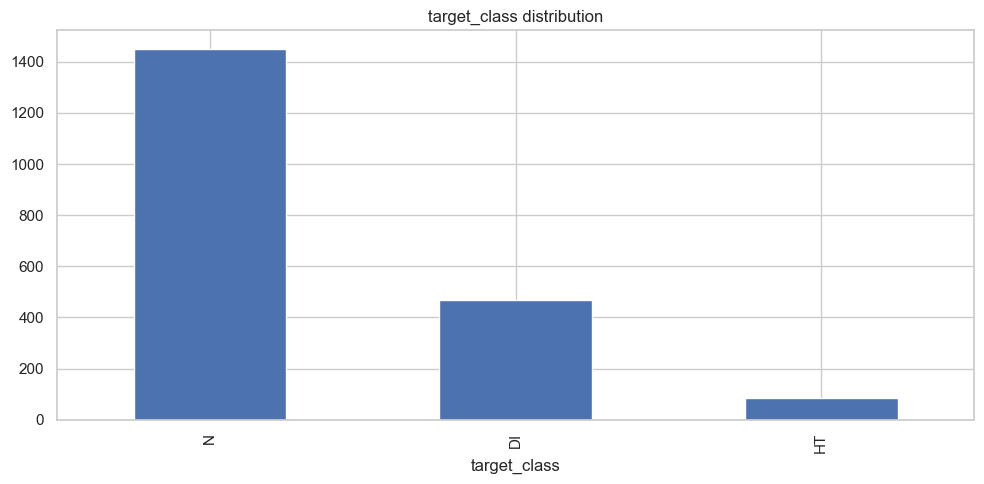

In [7]:
# Class balance
print('=== target_class distribution ===')
print(df['target_class'].value_counts())
df['target_class'].value_counts().plot(kind='bar', title='target_class distribution')
plt.tight_layout()
plt.show()

**O que faz:** Conta o número de instâncias por classe em `target_class` e representa essa distribuição num gráfico de barras.

**Porquê:** O desequilíbrio de classes é um dos problemas mais frequentes em classificação clínica. Se não for detetado, um classificador pode atingir alta *accuracy* simplesmente prevendo sempre a classe maioritária (ex.: prever sempre *N* daria 72.5% de acerto sem aprender nada).

**Resultado Obtido:** N >> DI >> HT — desequilíbrio severo que obriga ao uso de `StratifiedKFold` e métricas como F1 macro.

### 2.3 Descriptive Statistics

In [8]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,2.218212e+01,2.000000,29.000000,47.000000,65.000000,89.000000
age_normalized,2000.0,0.514695,2.549668e-01,0.000000,0.310345,0.517241,0.724137,1.000000
bmi,2000.0,27.097259,6.675740e+00,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372e+00,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,2.824913e+01,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802e+00,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,6.464608e+01,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680e+00,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,9.515382e-01,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,9.350002e-01,5.384979,12.287763,12.503725,12.691084,19.950612


>`describe(include='all')` mistura colunas numéricas e categóricas numa única tabela, o que gera colunas inteiramente preenchidas com `NaN` — as estatísticas numéricas (`mean`, `std`, `min`, quartis, `max`) não se aplicam a variáveis categóricas, e as métricas de frequência (`unique`, `top`, `freq`) não se aplicam a variáveis numéricas. Para uma leitura mais limpa e interpretável, filtra-se o `describe()` às **colunas numéricas** apenas.

Calculou-se as estatísticas descritivas (média, desvio-padrão, quartis, min, max) apenas para as features numéricas.

**O que procurar:** outliers (max muito afastado do Q3), features com desvio-padrão próximo de zero (potencial variância constante), e médias em zonas de risco clínico.

### 2.4 Univariate Analysis

De seguida, foi elaborado histogramas de 30 bins para cada feature numérica (excluindo `target_regression`), organizados numa grelha de 4 colunas.

**Porquê:** Os histogramas revelam:
- **Forma da distribuição** — normal, assimétrica, bimodal ou uniforme;
- **Outliers** — caudas longas ou barras isoladas;
- **Features constantes** — barra única (ex.: `calcium_baseline`);
- **Features com distribuição muito concentrada** — possível variável derivada (ex.: `blood_pressure` com std=4.22).

Estas observações justificam diretamente as decisões de tratamento na secção 2.6.

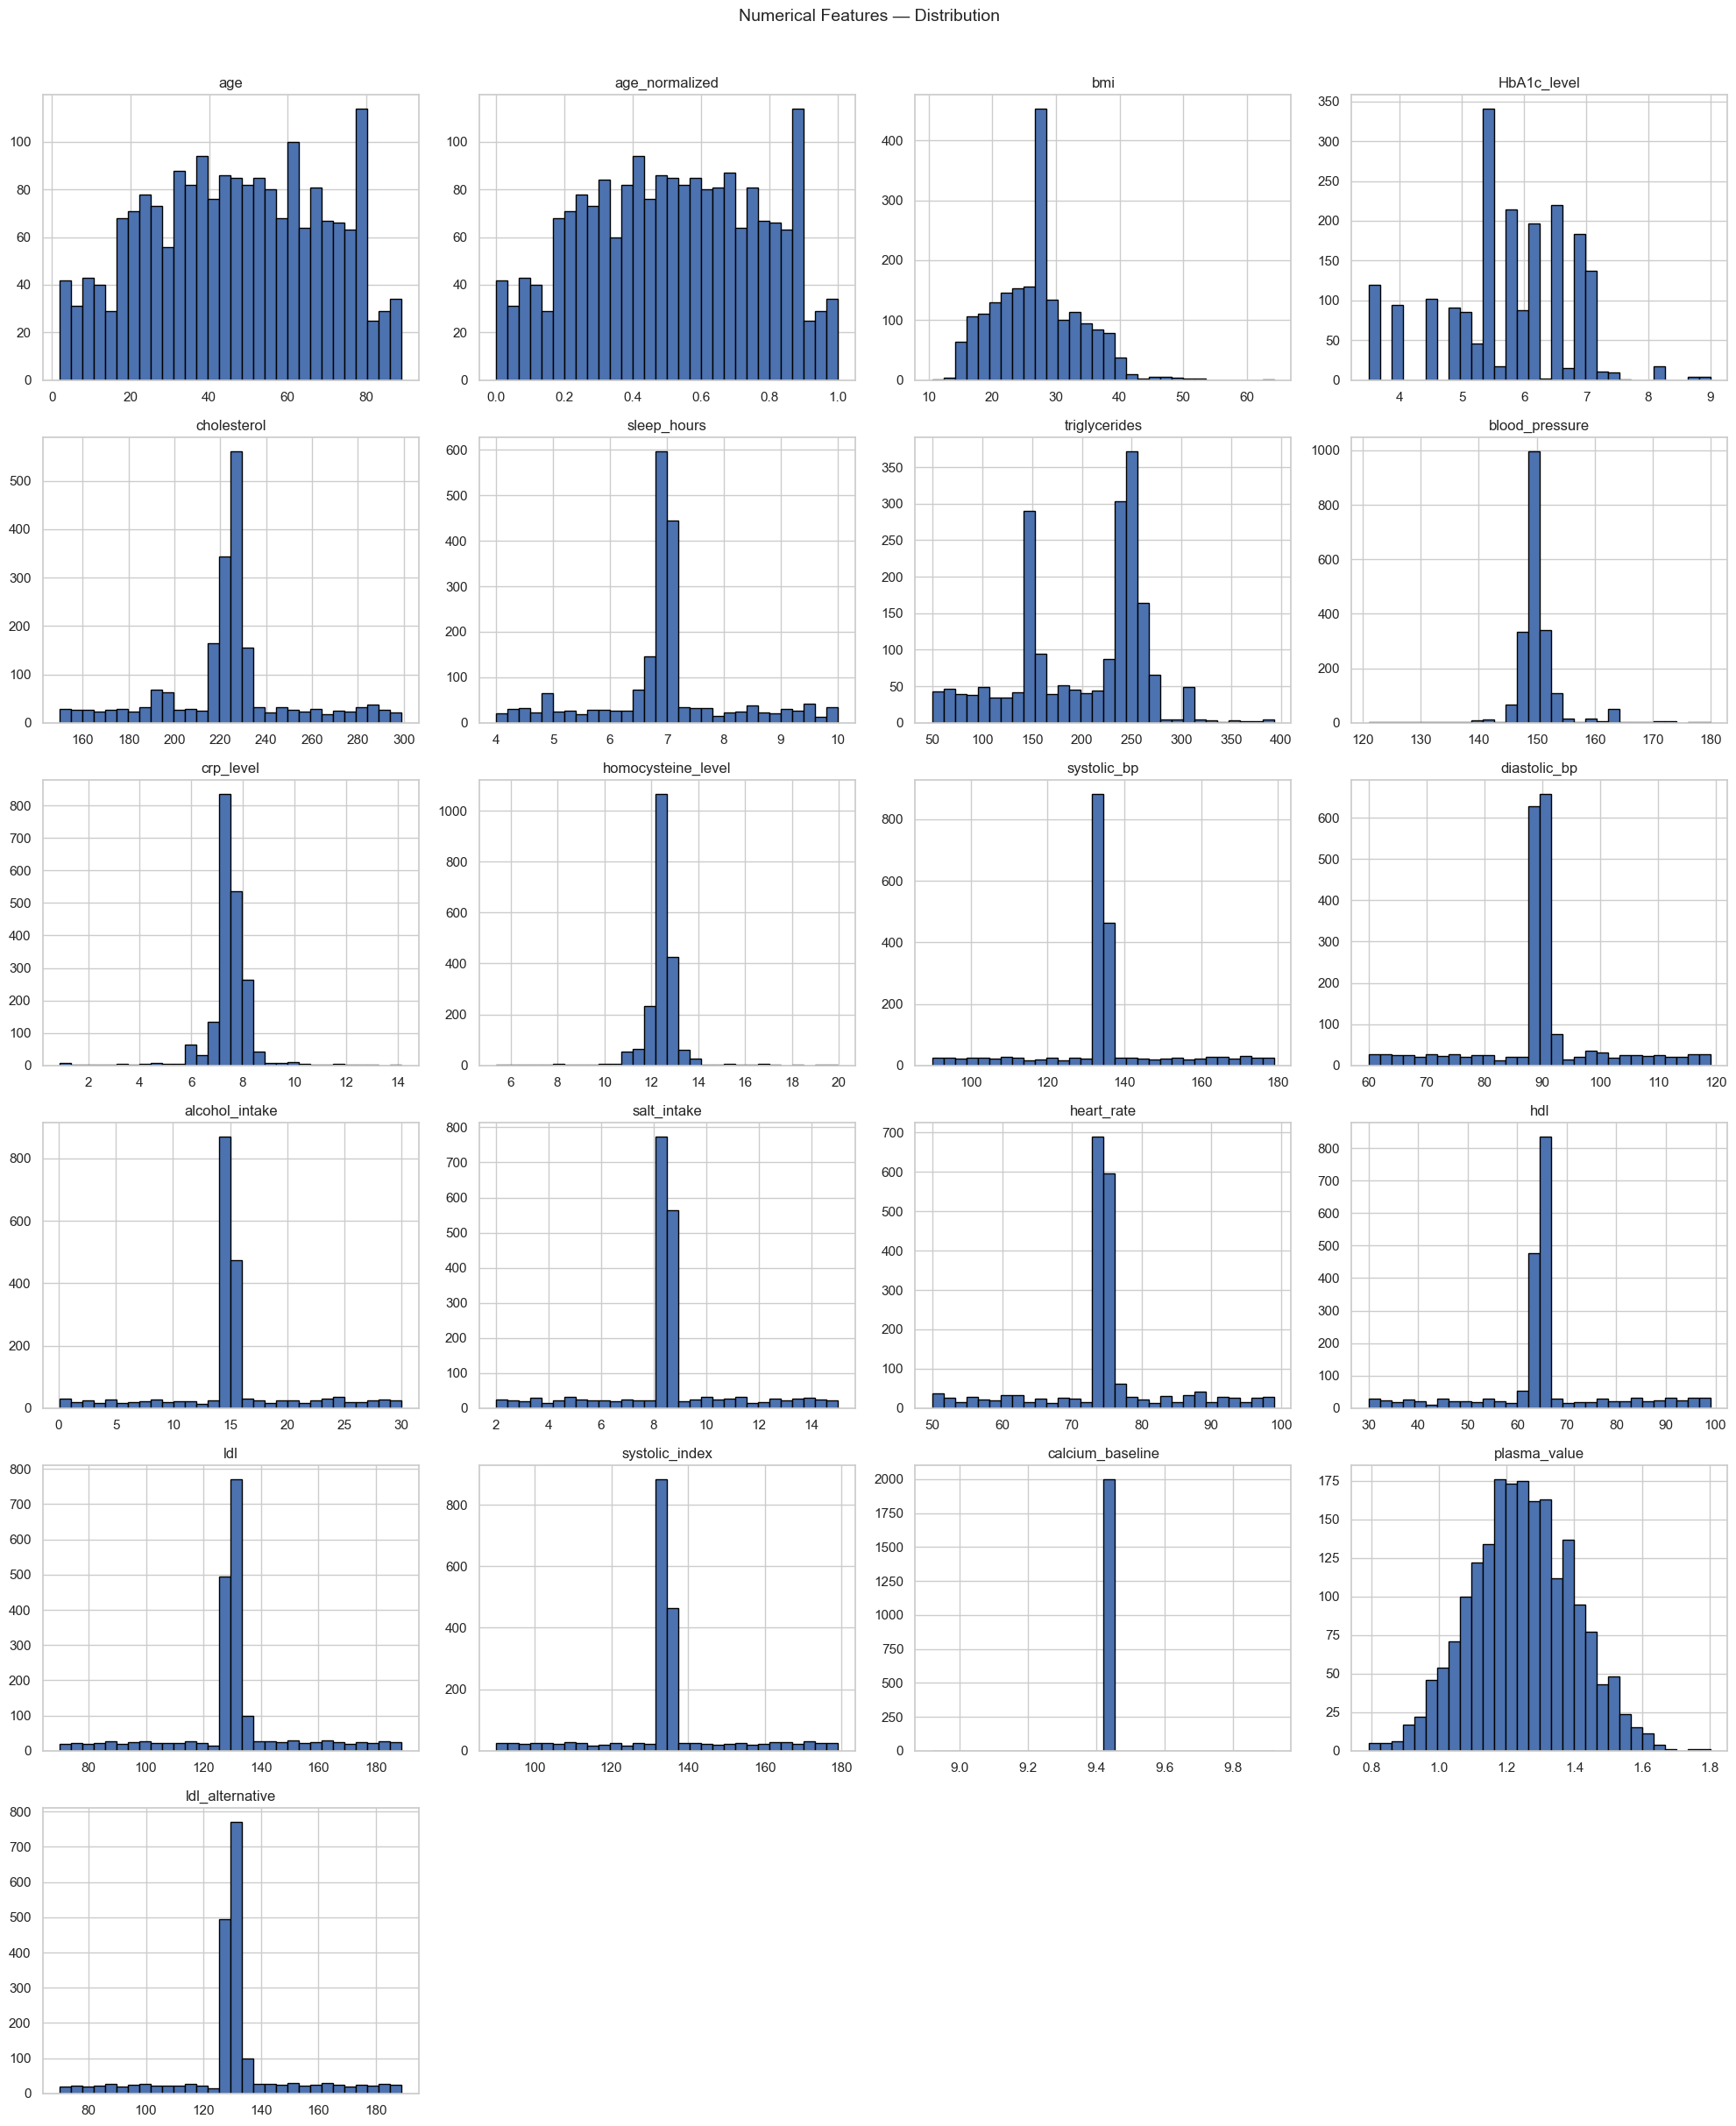

In [9]:
# Histograms for numerical features
num_features = [c for c in numerical_cols if c not in ['target_regression']]
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numerical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Features Numéricas

1. **Vários histogramas revelam padrões de imputação massiva.** As variáveis `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `systolic_index` e `ldl_alternative` apresentam todas o mesmo padrão: uma barra central dominante com caudas muito reduzidas. Isto indica que a maioria das observações tem valores calculados a partir de médias ou regras de imputação, e não medições diretas. Estas variáveis têm, por isso, baixo poder discriminante real para os modelos.

2. **Quatro variáveis bimodais sugerem heterogeneidade clínica real na população.** `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, evidenciando a existência de dois subgrupos populacionais com perfis de risco diferentes. Em `triglycerides`, os picos surgem a ~150 e ~230 mg/dL; em `crp_level` e `homocysteine_level`, um grupo com valores baixos (risco reduzido) e um grupo dominante com valores elevados (risco inflamatório/cardiovascular aumentado). Em `alcohol_intake`, os dois picos refletem dois padrões de consumo opostos. Esta bimodalidade pode ser informativa para a classificação.

3. **`calcium_baseline` tem variância zero e foi removida.** O histograma confirma visualmente o que as estatísticas descritivas já indicavam: uma única barra no valor 9.42 sem qualquer dispersão. Uma variável constante não transmite nenhuma informação ao modelo e foi, por isso, eliminada no passo de tratamento de dados.

4. **Três pares de variáveis redundantes foram identificados e um elemento de cada par foi removido.** Os histogramas de `age` e `age_normalized` têm exatamente a mesma forma (transformação linear), os de `ldl` e `ldl_alternative` são sobreponíveis, e os de `systolic_bp` e `systolic_index` são idênticos. A análise de correlação confirmou |r| = 1.00 em todos os casos, justificando a remoção de um elemento de cada par.

5. **`plasma_value` é a única feature com distribuição genuinamente normal e contínua.** O seu histograma apresenta uma curva em forma de seno centrada em ~1.2–1.3, sem picos artificiais nem concentrações anómalas. É provável que corresponda a uma medição laboratorial direta sem imputação significativa.

6. **`bmi` apresenta assimetria à direita com cauda longa.** A maioria dos valores concentra-se entre 20 e 35 kg/m², mas a cauda estende-se até ~64 kg/m², indicando casos de obesidade mórbida extrema. Estes outliers não foram removidos por serem clinicamente plausíveis, mas podem influenciar modelos sensíveis à escala.


Falta depois analisar as features categóricas (excluindo `target_class`, que já foi analisada separadamente).

**Porquê:** Permite identificar:
- **Dominância de uma categoria** — pode indicar baixo poder discriminante (ex.: se 95% dos registos tiverem o mesmo valor, a feature é quase constante);
- **Distribuição esperável** — validar se as proporções fazem sentido clínico;
- **Encoding necessário** — confirmar o número de categorias distintas antes do LabelEncoding.

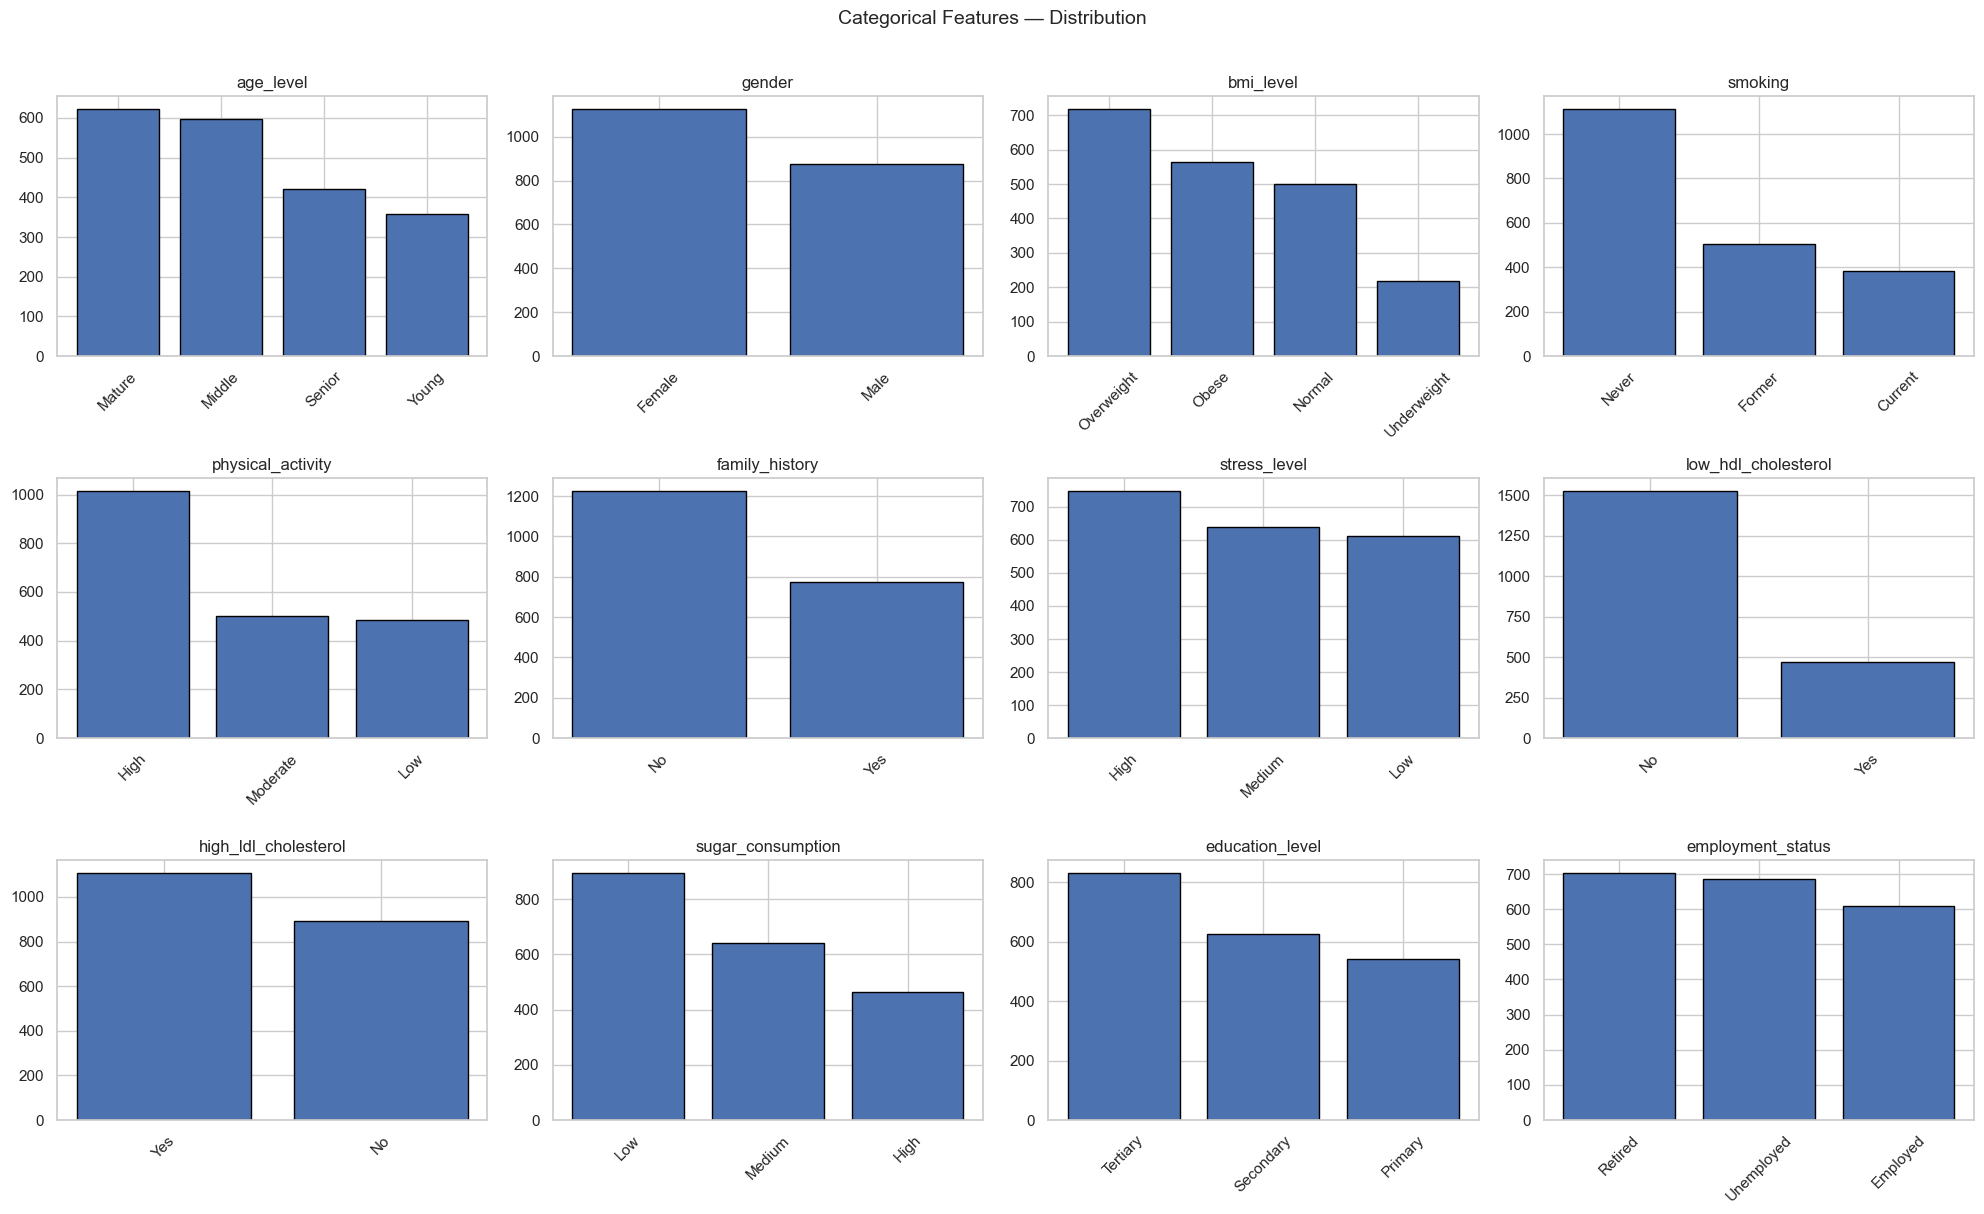

In [10]:
# Bar charts for categorical features
cat_features = [c for c in categorical_cols if c != 'target_class']
n = len(cat_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, edgecolor='black')
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Categorical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Features Categóricas

1. **Perfil clínico coerente com a população-alvo.** A predominância de `Mature` e `Senior` em `age_level`, combinada com `Overweight` e `Obese` em `bmi_level`, é consistente com um estudo de doenças cardiometabólicas. A exposição ao risco acumula-se com a idade e o excesso de peso é um fator de risco.

2. **Nenhuma categoria com dominância extrema.** Nenhuma feature tem uma classe com dominância extrema. Isto significa que todas as features têm pelo menos alguma variabilidade para o modelo aprender — ao contrário de `calcium_baseline` (que tem todos os seus values iguais), que foi removida.

3. **Paradoxo da atividade física.** `physical_activity` tem "High" como categoria mais frequente apesar do perfil de risco elevado da população. Isto pode refletir que a prática de atividade física é declarada (auto-reporte) e não necessariamente eficaz para mitigar outros fatores de risco. Esta feature pode ter baixo poder discriminante para `target_class` apesar da sua prevalência.

4. **`high_ldl_cholesterol` e `family_history` como potenciais preditores.** Ter LDL elevado  numa população maioritariamente saudável é clinicamente relevante: LDL elevado é um fator de risco independente. `family_history` é também substancial e difícil de controlar pelo indivíduo, tornando-a um marcador de risco estrutural.

5. **`employment_status` apresenta uma distribuição praticamente uniforme entre as três categorias. Do ponto de vista de entropia de informação, esta é a feature mais equilibrada do conjunto, mas a sua ligação direta ao desenvolvimento de diabetes ou hipertensão é menos óbvia do que as restantes, cabendo a etapa de Feature Selection determinar se o seu contributo e real.

### 2.5 Bivariate Analysis

Calculou-se a matriz de correlação de Pearson entre todas as features numéricas e visualiza-a como um heatmap anotado.

**Porquê:** A correlação de Pearson mede a força e direção da relação linear entre pares de variáveis. Valores altos (|r| ≥ 0.9) indicam:
- **Redundância** — manter ambas as features não acrescenta informação;
- **Multicolinearidade** — em modelos lineares, coeficientes de features altamente correlacionadas ficam instáveis.

Este gráfico é o primeiro diagnóstico de multicolinearidade e justifica a análise VIF mais formal na secção 2.6.

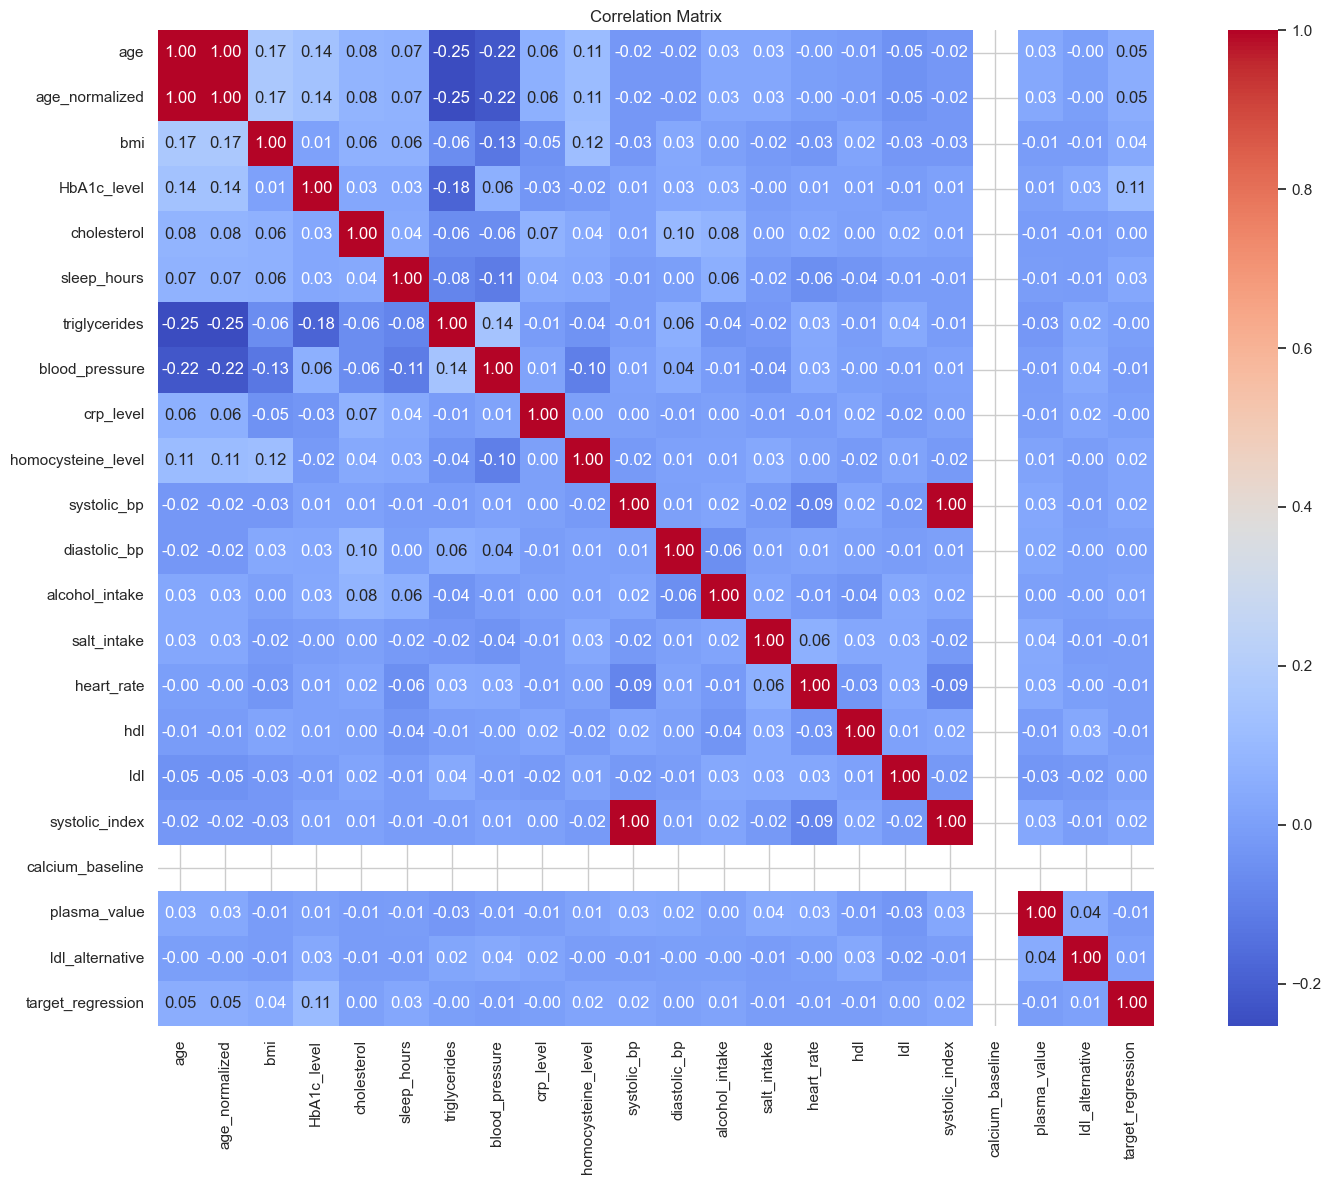

In [11]:
# Correlation heatmap (numerical features)
corr = df[numerical_cols].corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Conclusões: Matriz de Correlação

1. **A maioria das correlações é muito fraca.** Quase todos os pares de features apresentam valores de |r| < 0.15, o que confirma que as variáveis numéricas são amplamente independentes entre si. Isto é esperado dado que muitas delas resultam de imputação, o que atenua artificialmente as correlações.

2. **Três pares de variáveis perfeitamente correlacionadas foram identificados.** Os blocos vermelhos escuros com r = 1.00 entre `age` e `age_normalized`, entre `systolic_bp` e `systolic_index`, e entre `ldl` e `ldl_alternative` confirmam redundância total. Manter ambas as colunas num modelo introduziria multicolinearidade perfeita; um elemento de cada par foi removido no tratamento de dados.

3. **`calcium_baseline` aparece como linha e coluna em branco.** A ausência de qualquer cor na linha e coluna correspondentes reflete variância zero: uma feature constante tem correlação indefinida com qualquer outra variável. Foi removida por não conter informação discriminante.

4. **As correlações mais relevantes envolvem `triglycerides` e `blood_pressure` com `age`.** São as únicas correlações moderadas visíveis: `triglycerides` ↔ `age` (r = −0.25) e `blood_pressure` ↔ `age` (r = −0.22). Ambas são negativas, sugerindo que valores mais baixos destas variáveis estão associados a idades mais avançadas.

Plotar agora **boxplots** de cada feature numérica segmentada pelas três classes de `target_class`.

**Porquê:** Os boxplots bivariados permitem avaliar:
- **Poder discriminante de cada feature** — se as distribuições das classes se sobrepõem muito, a feature tem pouco valor classificatório;
- **Tendências clínicas** — ex.: `HbA1c_level` deve ser maior em classes diabéticas;
- **Outliers por classe** — identificar se outliers se concentram numa classe específica.

Esta análise orienta a seleção de features nas secções de Classificação e Feature Selection.

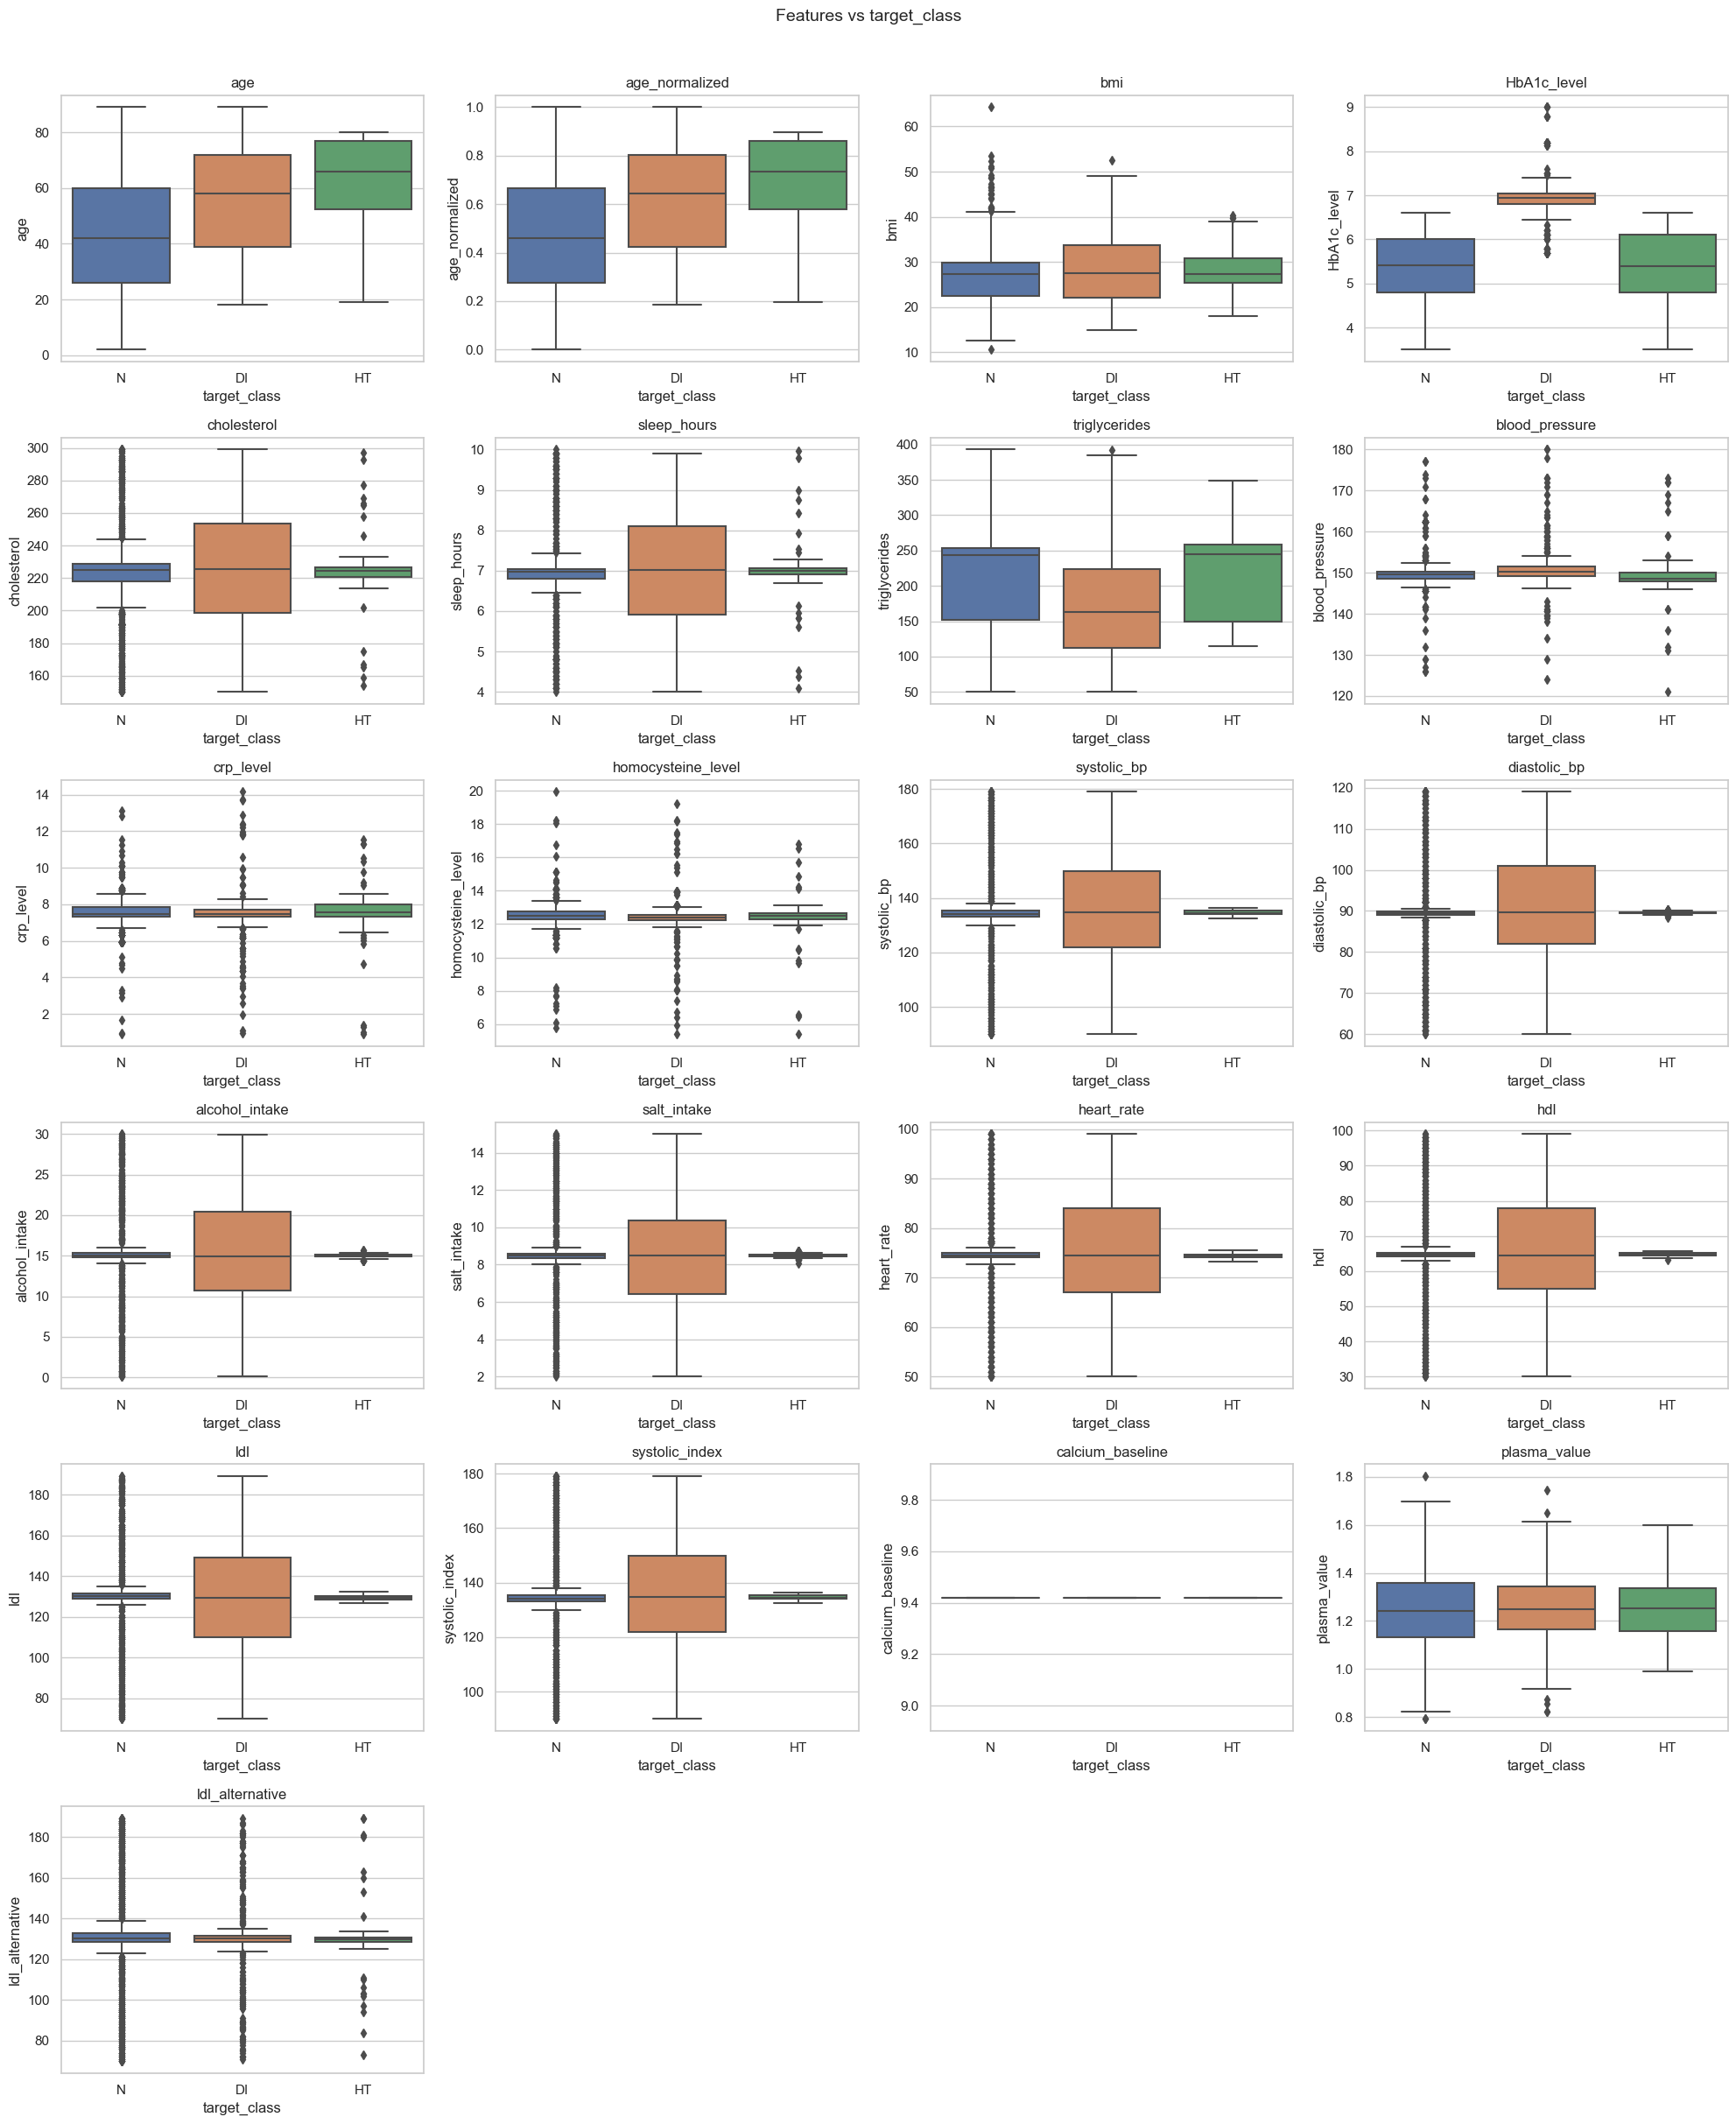

In [12]:
# Boxplots: numerical features vs target_class
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(x='target_class', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Features vs target_class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Boxplots Features vs `target_class`

1. **`age` e `HbA1c_level` são os melhores discriminadores visuais.** Em `age`, a mediana aumenta claramente de N  para DI e HT, com sobreposição reduzida entre as caixas: a idade é o fator que melhor separa as três classes. Em `HbA1c_level`, a classe DI tem mediana claramente superior face a N e HT, o que é clinicamente esperado: a hemoglobina glicada é o marcador de referência para diabetes.

2. **`bmi` discrimina DI das restantes classes.** A classe DI apresenta mediana de IMC visivelmente superior à de N e HT, consistente com a associação clínica entre obesidade e resistência à insulina. N e HT têm distribuições semelhantes entre si.

3. **A classe DI exibe sistematicamente caixas muito mais largas.** Em `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl` e `ldl_alternative`, N e HT apresentam IQR (Interquartile Range) extremamente estreito (boxplot quase achatado), enquanto DI tem IQR amplo. Isto confirma que as classes N e HT têm maioritariamente valores imputados (variância artificialmente baixa), ao passo que DI contém mais medições reais.

4. **`cholesterol`, `sleep_hours`, `crp_level`, `homocysteine_level` e `plasma_value` não separam as classes.** As três caixas são praticamente sobreponíveis em mediana e amplitude, tornando estas variáveis pouco úteis para a classificação.

5. **`blood_pressure` e `calcium_baseline` são completamente não-informativos.** Em `blood_pressure`, as três caixas são indistinguíveis (~149–151). Em `calcium_baseline`, as três classes reduzem-se a uma linha horizontal em 9.42 — variância zero confirma a sua remoção.

6. **`triglycerides` apresenta um padrão contra-intuitivo.** A classe N tem mediana de triglicéridos mais alta do que DI, o que contradiz a expectativa clínica. Pode refletir a natureza sintética/imputada do dataset ou que as classes DI e HT incluem doentes já medicados.

Foi calculada as correlações absolutas de todas as features numéricas com `target_regression`, ordenada por força de correlação, e plota scatter plots das top-6.

**Porquê:** Para a tarefa de regressão, o coeficiente de Pearson é um indicador rápido (mas limitado) de utilidade de cada feature como predictor linear. Features com |r| baixo produzirão modelos com R² baixo.

**Limitação conhecida:** Pearson captura apenas relações *lineares*. Uma feature pode ser útil via relações não-lineares mesmo com |r| baixo — mas os modelos que vamos usar (Regressão Linear) também são lineares, tornando este indicador adequado.

**Resultado esperado:** Correlações muito fracas (max ~0.1) — antecipa dificuldade na tarefa de regressão.

Top correlations with target_regression:
HbA1c_level           0.106513
age_normalized        0.053761
age                   0.053761
bmi                   0.036418
sleep_hours           0.026823
systolic_index        0.018374
systolic_bp           0.018374
homocysteine_level    0.018204
alcohol_intake        0.014946
blood_pressure        0.011194
Name: target_regression, dtype: float64


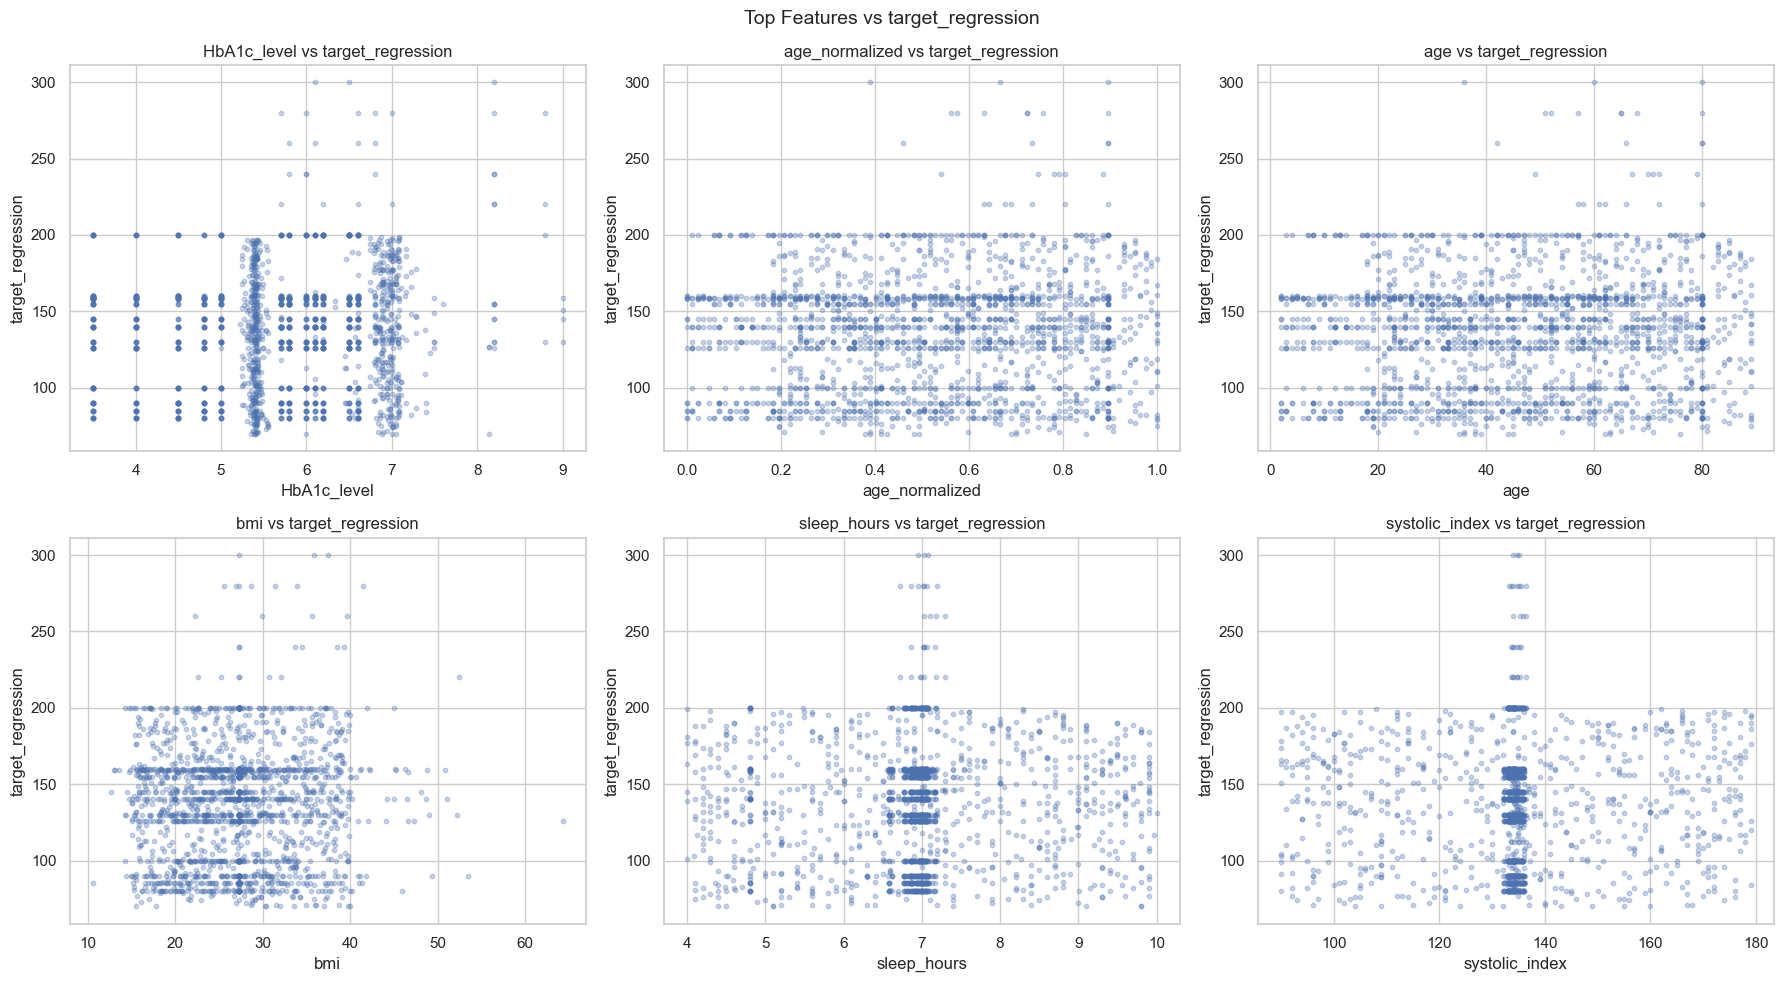

In [13]:
# Scatter: top correlated features vs target_regression
corr_with_target = df[numerical_cols].corr()['target_regression'].drop('target_regression').abs().sort_values(ascending=False)
print('Top correlations with target_regression:')
print(corr_with_target.head(10))

top_features = corr_with_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(top_features):
    axes[i].scatter(df[col], df['target_regression'], alpha=0.3, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_regression')
    axes[i].set_title(f'{col} vs target_regression')

plt.suptitle('Top Features vs target_regression', fontsize=14)
plt.tight_layout()
plt.show()

### Conclusões: Scatter Plots — Top Features vs `target_regression`

1. **Nenhuma feature tem relação linear expressiva com `target_regression`.** O valor máximo de correlação é |r| = 0.107 (`HbA1c_level`), muito abaixo do limiar convencional de correlação fraca (|r| = 0.3). Todos os scatter plots confirmam visualmente a ausência de tendência linear — os pontos distribuem-se em nuvens sem inclinação discernível.

2. **`HbA1c_level` é o melhor predictor, mas ainda insuficiente.** No seu scatter, observa-se que valores mais altos de HbA1c tendem ligeiramente a associar-se a valores mais altos de `target_regression`, mas a dispersão vertical é tão grande que essa tendência é quase invisível. O agrupamento em colunas verticais (valores discretos de HbA1c) reforça que muitas observações têm valores imputados por categoria clínica.

3. **`sleep_hours` e `systolic_index` revelam imputação massiva nos scatter plots.** Ambos mostram uma concentração extrema de pontos numa banda vertical estreita (~7h e ~134, respetivamente), com `target_regression` a variar de 70 a 300 nessa mesma banda — confirma que estas variáveis têm quase todos os valores imputados e por isso não explicam nada do alvo.

4. **Os pares redundantes são visíveis nas correlações idênticas.** `age` e `age_normalized` têm exatamente o mesmo |r| = 0.0538, e `systolic_index` e `systolic_bp` têm exatamente |r| = 0.0184 — prova matemática de que são a mesma informação.

5. **`target_regression` apresenta valores semi-discretos.** Nos scatter plots são visíveis bandas horizontais a valores redondos (90, 100, 130, 140, 160, 200, …), sugerindo que o próprio alvo de regressão tem uma distribuição discreta ou foi arredondado, o que limita ainda mais a capacidade dos modelos lineares contínuos de o aproximar.

### 2.6 Data Treatment

**O que a EDA revelou:**
- **`calcium_baseline`** — o histograma mostrou uma única barra em 9.42 (variância zero), confirmado pelas estatísticas descritivas (std ≈ 0). Não transmite qualquer informação discriminante.
- **`systolic_index`** — histograma e boxplots idênticos aos de `systolic_bp`; a matriz de correlação confirmou r = 1.00. É um duplicado exato.
- **`age_normalized`** — transformação linear de `age` (r = 1.00 na matriz de correlação). Manter ambas introduziria multicolinearidade perfeita nos modelos lineares.

Manter estas features não acrescenta informação preditiva e pode causar erros de inversão de matrizes em modelos lineares e LDA.

In [14]:
# --- 1. Constant features (nunique == 1 is more robust than std == 0) ---
constant_cols = [c for c in numerical_cols if df[c].nunique() == 1]
print('Constant features (zero variance):', constant_cols)

# --- 2. Redundant features ---
# 2a. Exact duplicates (bit-for-bit identical columns)
redundant_cols = set()
num_list = list(numerical_cols)
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and df[num_list[i]].equals(df[num_list[j]]):
            redundant_cols.add(num_list[j])
            print(f'  DUPLICATE : "{num_list[i]}" == "{num_list[j]}"  →  dropping "{num_list[j]}"')

# 2b. Perfect linear correlation (|r| >= 0.9999 catches derived/scaled columns)
corr_matrix = df[num_list].corr().abs()
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and corr_matrix.iloc[i, j] >= 0.9999:
            redundant_cols.add(num_list[j])
            print(f'  CORR≈1.0  : "{num_list[i]}" ↔ "{num_list[j]}" (r={corr_matrix.iloc[i, j]:.8f})  →  dropping "{num_list[j]}"')

print('\nColumns to remove:', sorted(constant_cols + list(redundant_cols)))

Constant features (zero variance): ['calcium_baseline']
  DUPLICATE : "systolic_bp" == "systolic_index"  →  dropping "systolic_index"
  CORR≈1.0  : "age" ↔ "age_normalized" (r=1.00000000)  →  dropping "age_normalized"

Columns to remove: ['age_normalized', 'calcium_baseline', 'systolic_index']


**O que faz:** Remove de `df` as features identificadas como constantes ou redundantes e guarda o resultado em `df_clean`.

**Porquê:** Separar a fase de *deteção* da fase de *aplicação* permite rever os resultados antes de os aplicar. Após esta célula, o dataset está livre de informação duplicada — a matriz de correlação confirmou visualmente que as features removidas são intercambiáveis com as que ficam.

In [15]:
# --- 3. Apply treatment ---
cols_to_drop = list(set(constant_cols) | redundant_cols)
print('Columns to drop:', sorted(cols_to_drop))

df_clean = df.drop(columns=cols_to_drop)
print(f'\nOriginal shape : {df.shape}')
print(f'Cleaned shape  : {df_clean.shape}')

Columns to drop: ['age_normalized', 'calcium_baseline', 'systolic_index']

Original shape : (2000, 35)
Cleaned shape  : (2000, 32)


**O que faz:** Exporta `df_clean` para `dataset_grupo_18_cleaned.csv` no mesmo diretório do dataset original.

**Porquê:** Persistir o dataset limpo permite:
- Usar o ficheiro diretamente noutros contextos (ex.: comparação com ferramentas externas);
- Garantir reprodutibilidade — o mesmo ficheiro é carregado pelas versões individuais dos notebooks;
- Servir como ponto de inspeção manual (pode ser aberto no Excel/Sheets).

In [16]:
# Save cleaned dataset for external use
CLEANED_PATH = DATASET_PATH.replace('dataset_grupo_18.csv', 'dataset_grupo_18_cleaned.csv')
df_clean.to_csv(CLEANED_PATH, index=False)
print(f'Cleaned dataset saved to {CLEANED_PATH}')
print(f'Final shape: {df_clean.shape}')
print(f'Remaining features: {df_clean.columns.tolist()}')

Cleaned dataset saved to ../dataset_grupo_18_cleaned.csv
Final shape: (2000, 32)
Remaining features: ['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class']


**O que faz:** Calcula estatísticas descritivas apenas das features numéricas do dataset limpo final.

**Porquê:** Permite confirmar que o tratamento de dados produziu o resultado esperado:
- O shape reduzido (menos colunas numéricas) é visível;
- As estatísticas das features sobreviventes (`age`, `alcohol_intake`) são validadas;
- Serve de ponto de referência para comparar com as estatísticas do dataset original.

In [17]:
df_clean.select_dtypes(include=[np.number]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,22.182120,2.000000,29.000000,47.000000,65.000000,89.000000
bmi,2000.0,27.097259,6.675740,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,28.249128,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,64.646075,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,0.951538,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,0.935000,5.384979,12.287763,12.503725,12.691084,19.950612
systolic_bp,2000.0,134.460825,15.782950,90.000000,133.052402,134.167413,135.590248,179.000000


### Conclusões: Data Treatment

O pipeline de tratamento de dados removeu **3 das 22 features numéricas originais**, reduzindo o dataset de (2000 × 35) para (2000 × 32):

| Passo | Features removidas | Critério | Evidência da EDA |
|---|---|---|---|
| Variância zero | `calcium_baseline` | nunique == 1 | Histograma com barra única em 9.42 |
| Redundância exata | `systolic_index` | r = 1.000 com `systolic_bp` | Matriz de correlação + boxplots idênticos |
| Correlação perfeita | `age_normalized` | r = 1.000 com `age` | Bloco vermelho escuro na matriz de correlação |

**Dataset limpo (2000 × 32):** mantém todas as features numéricas com variabilidade real, incluindo `age`, `bmi`, `HbA1c_level`, `cholesterol`, `triglycerides`, `alcohol_intake`, entre outras. As features com padrões de imputação massiva (spike nos histogramas) permanecem — o seu impacto nos modelos será avaliado na etapa de Feature Selection.

## 7. Conclusões da EDA

### 7.1 Estatísticas Descritivas

As estatísticas descritivas (calculadas apenas sobre features numéricas, para evitar NaN de métricas inaplicáveis a categóricas) revelam uma população com perfil de risco cardiometabólico elevado:

| Observação | Valor | Interpretação clínica |
|---|---|---|
| `cholesterol` médio | 223.5 mg/dL | Acima do limiar borderline (≥ 200) |
| `triglycerides` médio | 201.1 mg/dL | Limiar de risco moderado (≥ 150) |
| `crp_level` médio | 7.5 | Inflamação vascular elevada (> 3) |
| `homocysteine_level` médio | 12.4 µmol/L | Risco cardiovascular (> 10) |
| `bmi` máximo | 64.3 kg/m² | Obesidade mórbida extrema — cauda longa à direita |
| `blood_pressure` std | 4.22 para amplitude 59 | Desvio-padrão anormalmente baixo — medida derivada/imputada |
| `calcium_baseline` | sempre 9.42 | **Variância zero** — sem informação discriminante, removida |

---

### 7.2 Análise Univariada

**Numéricas — padrões principais:**
- **Imputação massiva** — `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `ldl_alternative` apresentam uma barra central dominante com caudas muito reduzidas, indicando que a maioria dos valores foi imputada por médias populacionais.
- **Bimodal** — `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, sugerindo dois subgrupos populacionais com perfis de risco diferentes.
- **`plasma_value`** — única feature com distribuição genuinamente normal e contínua.
- **`bmi`** — assimétrica à direita com cauda até 64.3 kg/m².
- **`calcium_baseline`** — barra única em 9.42 → variância zero → removida.

**Categóricas — desequilíbrio crítico de `target_class`:**

```
N  → 1450  (72.5%)   ← classe maioritária
DI →  467  (23.4%)
HT →   83  ( 4.1%)   ← classe minoritária severa
```

> ⚠️ Um classificador que preveja sempre *N* obtém **72.5% de accuracy** sem aprender nada. Métricas de avaliação devem incluir **F1 macro** e **recall por classe**, não apenas accuracy. `StratifiedKFold` é obrigatório para preservar as proporções em todos os folds.

---

### 7.3 Análise Bivariada

**Matriz de correlação — pares redundantes confirmados:**
- `systolic_bp` ↔ `systolic_index`: r = 1.000 (duplicado exato)
- `age` ↔ `age_normalized`: r = 1.000 (transformação linear)
- Restantes correlações: |r| < 0.15 — dataset amplamente não-correlacionado; a imputação massiva atenua artificialmente as correlações entre as features afetadas.

**Boxplots vs `target_class`:**
- `age` e `HbA1c_level` são os melhores discriminadores visuais — medianas claramente distintas entre N, DI e HT.
- `bmi` discrimina DI das restantes classes.
- A classe DI apresenta IQR sistematicamente mais largo do que N e HT em múltiplas features, revelando maior presença de medições reais (vs. imputadas).

**Correlações com `target_regression` — todas fracas:**

| Feature | \|r\| |
|---|---|
| `HbA1c_level` | **0.107** ← melhor predictor |
| `age` | 0.054 |
| `bmi` | 0.036 |
| `sleep_hours` | 0.027 |
| `systolic_bp` | 0.018 |
| `homocysteine_level` | 0.018 |
| `alcohol_intake` | 0.015 |

> ⚠️ O limiar convencional de correlação fraca é |r| = 0.3. **Nenhuma feature sequer o atinge.** Os scatter plots confirmam ausência de tendências lineares claras e revelam que `target_regression` tem valores semi-discretos (bandas horizontais em valores redondos), o que limita ainda mais os modelos lineares. Os R² baixos são uma propriedade do dataset, não uma falha metodológica.

---

### 7.4 Tratamento de Dados

**Remoção de features não informativas/redundantes (35 → 32 colunas):**

| Feature removida | Motivo |
|---|---|
| `calcium_baseline` | Variância zero (valor único = 9.42) — zero poder discriminante |
| `systolic_index` | Duplicado exato de `systolic_bp` (r = 1.000) |
| `age_normalized` | Transformação linear de `age` (r = 1.000) — preferível manter a escala original |

**Valores em falta:** nenhum encontrado — nem NaN reais nem strings NaN ocultas nas categóricas. Dataset completamente preenchido.

---

### 7.5 Dataset Final

O dataset exportado (`dataset_grupo_18_cleaned.csv`) tem **2000 × 32**:

| Tipo | Features |
|---|---|
| **Categóricas (12)** | `age_level`, `gender`, `bmi_level`, `smoking`, `physical_activity`, `family_history`, `stress_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol`, `sugar_consumption`, `education_level`, `employment_status` |
| **Numéricas (18)** | `age`, `bmi`, `HbA1c_level`, `cholesterol`, `sleep_hours`, `triglycerides`, `blood_pressure`, `crp_level`, `homocysteine_level`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `plasma_value`, `ldl_alternative` |
| **Alvos (2)** | `target_regression`, `target_class` |

**Implicações para os passos seguintes:**
1. **Regressão**: correlações lineares com `target_regression` são todas fracas (max |r| = 0.107) e o alvo é semi-discreto → esperar R² baixos nos modelos lineares.
2. **Classificação**: desequilíbrio severo (72.5% / 23.4% / 4.1%) → usar `StratifiedKFold` + F1 macro como métrica principal.
3. **Feature selection**: presença de features com imputação massiva — Ridge e Lasso deverão atribuir-lhes coeficientes baixos por não discriminarem as classes/alvo.

---
## Shared Preprocessing

Encode `df_clean` once for all supervised learning tasks.

Aplicar `LabelEncoder` a todas as colunas categóricas de `df_clean`, definir a lista de features (excluindo ambos os alvos), e criar `X_scaled` (StandardScaler) e `y_class` para uso nas secções de Classificação e Feature Selection.

**Porquê — LabelEncoder:** Converte categorias em inteiros para que os modelos sklearn (que só aceitam input numérico) possam processar as features categóricas. **Alternativa:** `OneHotEncoder` evitaria relações ordinais artificiais entre categorias — mas para LDA e Regressão Logística com poucas categorias, LabelEncoder é uma simplificação comum.

**Porquê — StandardScaler:** Normaliza as features para média=0 e desvio-padrão=1. É necessário para:
- **Regressão Logística** — o solver gradient-based converge mais rápido com features na mesma escala;
- **LDA** — assume covariâncias homogéneas; features com escalas muito diferentes desequilibrariam as distâncias.

**Porquê aqui e não em cada secção:** Centralizar evita inconsistências — re-fazer o fit do scaler em dados diferentes produziria transformações ligeiramente diferentes. O `fit` é feito sobre todo o dataset (antes de qualquer split) porque é apenas para exploração; nos splits subsequentes, o scaler já está fixo.

In [18]:
# Label-encode all categorical columns
df_enc = df_clean.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

# Feature list (excludes both targets)
FEATURES = [c for c in df_enc.columns if c not in ['target_regression', 'target_class']]
feature_names = np.array(FEATURES)

# Scaled matrix for classification / feature selection
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_enc[FEATURES].values)
y_class  = df_enc['target_class'].values

print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'X_scaled: {X_scaled.shape}')
print(f'Class distribution: {dict(zip(*np.unique(y_class, return_counts=True)))}')

Features (30): ['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'plasma_value', 'ldl_alternative']
X_scaled: (2000, 30)
Class distribution: {0: 467, 1: 83, 2: 1450}


---
## 3. Regression — Predicting `target_regression`

Aqui vamos definir o alvo de regressão (`y_reg`), criar a matriz de features como DataFrame (para permitir seleção por nome de coluna), e dividir em treino/teste com proporção 80/20.

**Porquê 80/20:** Compromisso standard entre ter dados suficientes para treinar (80%) e uma amostra de teste representativa (20% = 400 instâncias).

**Porquê sem `stratify`:** Ao contrário da classificação, `target_regression` é contínua — não há classes para estratificar. A divisão aleatória com `random_state=42` é suficiente para reprodutibilidade.

**Porquê sem StandardScaler aqui:** A Regressão Linear Ordinária (OLS) é invariante à escala das features — escalar não altera os R², MAE ou RMSE, apenas os coeficientes estimados. Manter as features não-escaladas facilita a interpretação direta dos coeficientes.

In [19]:
# Regression uses unscaled label-encoded features
y_reg = df_enc['target_regression'].values
X_reg = df_enc[FEATURES]  # DataFrame for column selection by name

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train: {X_train_r.shape} | Test: {X_test_r.shape}')

Train: (1600, 30) | Test: (400, 30)


**O que faz:** Define uma função auxiliar `evaluate_reg` que calcula e imprime R², MAE e RMSE para um par (y_true, y_pred), retornando-os num dicionário.

**Métricas utilizadas:**
- **R²** (*coeficiente de determinação*) — proporção da variância de `target_regression` explicada pelo modelo. R²=0 significa que o modelo não é melhor do que prever a média; R²<0 indica que é pior.
- **MAE** (*Mean Absolute Error*) — erro médio absoluto, na mesma unidade que o alvo; mais intuitivo e robusto a outliers do que RMSE.
- **RMSE** (*Root Mean Squared Error*) — penaliza erros grandes mais do que o MAE; útil quando erros grandes são mais prejudiciais.

**Porquê função e não código inline:** Evita repetição nas três variantes do modelo e garante que as métricas são calculadas de forma consistente.

In [20]:
def evaluate_reg(name, y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'[{name}]  R²={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}')
    return {'Model': name, 'R²': r2, 'MAE': mae, 'RMSE': rmse}

### 3.1 Simple Linear Regression

**O que faz:** Treina uma Regressão Linear Simples para cada feature individualmente e ordena os resultados por R² decrescente.

**Porquê:** Antes de escolher a "melhor feature" para o modelo simples, é necessário avaliá-las todas empiricamente — a correlação de Pearson (secção EDA) é um indicador mas não equivale ao R² de uma regressão (a relação pode ser não-linear ou o ruído pode ser heterocedástico).

**Porquê avaliar no conjunto de teste:** Evitar *overfitting* de seleção — se escolhêssemos a feature com maior R² no treino, poderíamos estar a selecionar uma que se ajustou por acaso aos dados de treino.

In [21]:
# Test each feature individually — rank by R²
reg_results_simple = []
for feat in FEATURES:
    m = LinearRegression()
    m.fit(X_train_r[[feat]], y_train_r)
    r2 = r2_score(y_test_r, m.predict(X_test_r[[feat]]))
    reg_results_simple.append({'Feature': feat, 'R²': r2})

results_simple_df = pd.DataFrame(reg_results_simple).sort_values('R²', ascending=False)
results_simple_df.head(10)

,Feature,R²
6,HbA1c_level,0.008299
11,family_history,0.001074
12,stress_level,0.001042
4,age,0.000096
2,bmi_level,-0.000148
0,age_level,-0.000307
10,physical_activity,-0.000727
1,gender,-0.000870
15,blood_pressure,-0.001010
27,employment_status,-0.001112


**O que faz:** Treina o modelo de Regressão Linear Simples com a feature de melhor R², avalia no conjunto de teste, e plota os valores reais vs. preditos.

**Porquê o scatter plot:** Visualizar a relação entre a melhor feature e as predições permite confirmar se a relação é realmente linear ou se há padrões sistemáticos (heterocedasticidade, tendência residual) que o modelo linear não captura. Um scatter completamente disperso sem tendência linear confirma a fraqueza do preditor.

Best single feature: HbA1c_level
[Simple LR]  R²=0.0083  MAE=30.8520  RMSE=38.3962


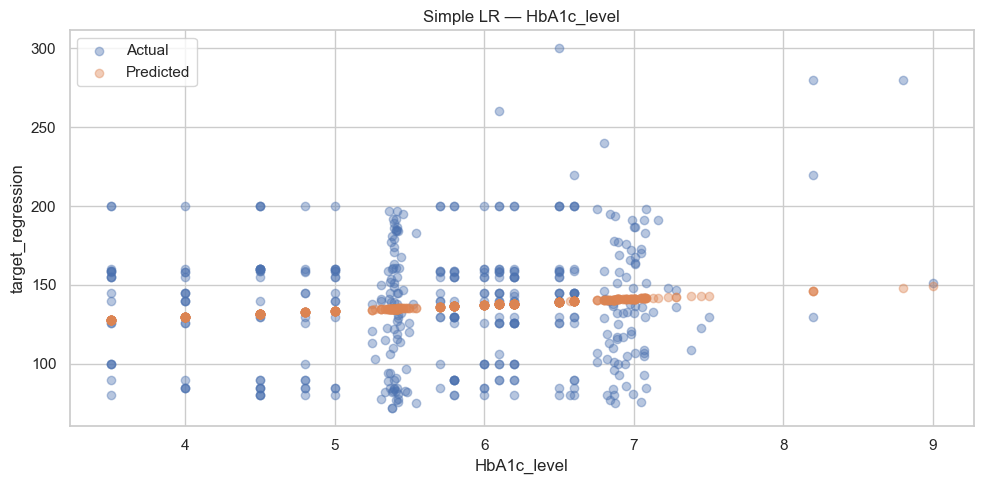

In [22]:
best_feat = results_simple_df.iloc[0]['Feature']
print(f'Best single feature: {best_feat}')

model_slr = LinearRegression()
model_slr.fit(X_train_r[[best_feat]], y_train_r)
y_pred_slr = model_slr.predict(X_test_r[[best_feat]])
reg_metrics = [evaluate_reg('Simple LR', y_test_r, y_pred_slr)]

plt.scatter(X_test_r[best_feat], y_test_r, alpha=0.4, label='Actual')
plt.scatter(X_test_r[best_feat], y_pred_slr, alpha=0.4, label='Predicted')
plt.xlabel(best_feat)
plt.ylabel('target_regression')
plt.legend()
plt.title(f'Simple LR — {best_feat}')
plt.tight_layout()
plt.show()

### 3.2 Multiple Linear Regression

**O que faz:** Treina uma Regressão Linear Múltipla com todas as features disponíveis.

**Porquê:** Serve como referência para o modelo múltiplo sem qualquer seleção de features. Um R² negativo ou próximo de zero com todas as features indica que adicionar mais variáveis não ajuda — pode até introduzir ruído que piora as predições (*curse of dimensionality* em datasets pequenos ou com features irrelevantes).

In [23]:
model_mlr_all = LinearRegression()
model_mlr_all.fit(X_train_r, y_train_r)
reg_metrics.append(evaluate_reg('Multiple LR (all features)', y_test_r, model_mlr_all.predict(X_test_r)))

[Multiple LR (all features)]  R²=-0.0319  MAE=31.6520  RMSE=39.1666


**O que faz:** Treina uma Regressão Linear Múltipla com as `TOP_N=5` features de maior R² individual (do ranking da Regressão Simples).

**Porquê:** A seleção por ranking univariado é uma heurística simples — não garante o subset ótimo (um método como *forward selection* seria mais rigoroso), mas é computacionalmente barata e frequentemente eficaz quando as features são relativamente independentes.

**Limitação:** As top-5 features por R² univariado podem ser redundantes entre si — se duas features capturam essencialmente a mesma variação, incluir ambas não melhora o modelo.

In [24]:
TOP_N = 5
top_feats = results_simple_df.head(TOP_N)['Feature'].tolist()
print(f'Top {TOP_N} features: {top_feats}')

model_mlr_top = LinearRegression()
model_mlr_top.fit(X_train_r[top_feats], y_train_r)
reg_metrics.append(evaluate_reg(f'Multiple LR (top {TOP_N})', y_test_r, model_mlr_top.predict(X_test_r[top_feats])))

Top 5 features: ['HbA1c_level', 'family_history', 'stress_level', 'age', 'bmi_level']
[Multiple LR (top 5)]  R²=0.0154  MAE=30.7743  RMSE=38.2582


### 3.3 Comparison & Discussion

**O que faz:** Constrói uma tabela comparativa dos três modelos de regressão (R², MAE, RMSE) e plota um gráfico de barras agrupado.

**Porquê:** A comparação simultânea das três métricas permite:
- Verificar se o modelo múltiplo melhora o simples (se não melhorar, as features adicionais são ruído);
- Identificar trade-offs (ex.: MAE melhorou mas RMSE piorou — há erros grandes ocasionais);
- Documentar os resultados de forma clara para o relatório.

,R²,MAE,RMSE
Model,,,
Simple LR,0.008299,30.851973,38.396230
Multiple LR (all features),-0.031896,31.652037,39.166624
Multiple LR (top 5),0.015416,30.774293,38.258204


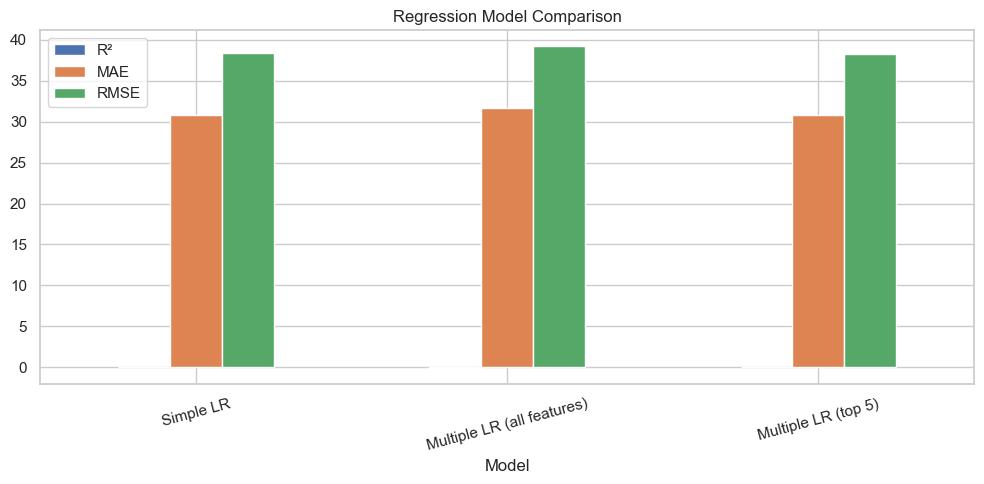

In [25]:
reg_metrics_df = pd.DataFrame(reg_metrics).set_index('Model')
display(reg_metrics_df)

reg_metrics_df[['R²', 'MAE', 'RMSE']].plot(kind='bar', figsize=(10, 5))
plt.title('Regression Model Comparison')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Discussion

- **Best single feature and justification:**
- **Best feature combination and justification:**
- **Simple vs Multiple LR comparison:**

---
## 4. Classification — Predicting `target_class`

Methods: **Logistic Regression** and **LDA**  
Resampling: Holdout | CV k=5 | CV k=10 | LOOCV | Bootstrap  
`StratifiedKFold` is used throughout to preserve class proportions given the imbalance (N=72.5%, DI=23.4%, HT=4.1%).

**O que faz:** Inicializa os dois classificadores (`LogisticRegression` e `LDA`) e define a lista de resultados e a função `record_clf` para registar métricas.

**Porquê Regressão Logística:**
- Modelo linear probabilístico — bem interpretável pelos coeficientes;
- Adequado para classificação multiclasse com `multi_class='auto'` (sklearn usa One-vs-Rest por defeito);
- `max_iter=1000` porque o dataset tem features categóricas codificadas que podem exigir mais iterações para convergência.

**Porquê LDA:**
- Assume distribuições gaussianas por classe com covariâncias iguais;
- Produz fronteiras de decisão lineares como a Regressão Logística, mas via critério diferente (maximizar separação entre classes);
- É particularmente útil para comparar: se LDA melhorar significativamente a LR, sugere que as distribuições gaussianas são uma boa aproximação.

In [26]:
clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LDA': LinearDiscriminantAnalysis()
}
clf_results = []

def record_clf(model_name, method, scores):
    clf_results.append({
        'Model': model_name,
        'Method': method,
        'Mean Accuracy': np.mean(scores),
        'Std': np.std(scores)
    })

### 4.1 Holdout

**O que faz:** Divide os dados em treino/teste (80/20) com `stratify=y_class`, treina ambos os classificadores, avalia com accuracy e classification report, e plota a matriz de confusão.

**Porquê `stratify=y_class`:** Com desequilíbrio severo (HT=4.1%), uma divisão aleatória pode colocar pouquíssimas instâncias HT no teste, tornando a avaliação pouco representativa. A estratificação garante que as proporções N/DI/HT são mantidas em treino e teste.

**Porquê a matriz de confusão:** A *accuracy* isolada é enganosa em datasets desequilibrados. A matriz de confusão mostra especificamente onde o modelo falha — se classificar todos como *N* e obter 72.5%, a matriz revelará linhas DI e HT completamente erradas.

**Limitação do Holdout:** Uma única divisão treino/teste pode ser otimista ou pessimista por acaso — daí a necessidade dos métodos de validação cruzada seguintes.

Logistic Regression — Holdout Accuracy: 0.9175
              precision    recall  f1-score   support

           0       0.89      0.92      0.91        93
           1       0.00      0.00      0.00        17
           2       0.93      0.97      0.95       290

    accuracy                           0.92       400
   macro avg       0.61      0.63      0.62       400
weighted avg       0.88      0.92      0.90       400



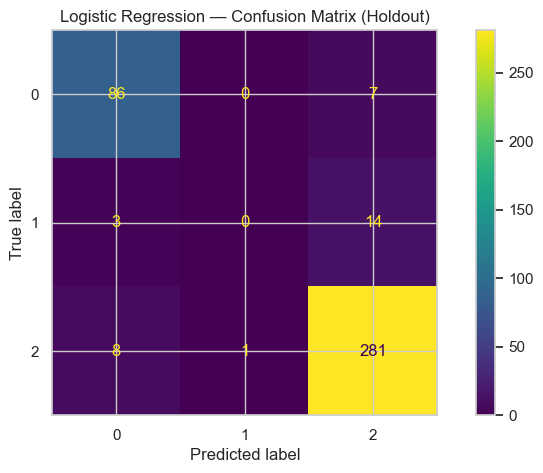

LDA — Holdout Accuracy: 0.8925
              precision    recall  f1-score   support

           0       0.90      0.83      0.86        93
           1       0.20      0.06      0.09        17
           2       0.90      0.96      0.93       290

    accuracy                           0.89       400
   macro avg       0.67      0.62      0.63       400
weighted avg       0.87      0.89      0.88       400



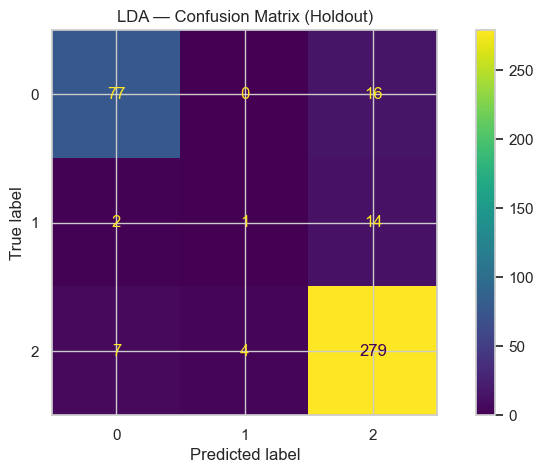

In [27]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_scaled, y_class, test_size=0.2, stratify=y_class, random_state=RANDOM_STATE
)

for name, model in clf_models.items():
    model.fit(X_train_c, y_train_c)
    y_pred = model.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    record_clf(name, 'Holdout', [acc])
    print(f'{name} — Holdout Accuracy: {acc:.4f}')
    print(classification_report(y_test_c, y_pred))
    disp = ConfusionMatrixDisplay(confusion_matrix(y_test_c, y_pred))
    disp.plot()
    plt.title(f'{name} — Confusion Matrix (Holdout)')
    plt.show()

### 4.2 Cross-Validation — Stratified k-Fold (k=5 and k=10)

`StratifiedKFold` guarantees that each fold preserves the original class proportions.

**O que faz:** Avalia ambos os classificadores com Stratified K-Fold para k=5 e k=10, registando a média e desvio-padrão de accuracy em cada fold.

**Porquê Stratified K-Fold em vez de K-Fold simples:** Em datasets desequilibrados, K-Fold simples pode criar folds onde uma classe minoritária está sub-representada ou ausente, levando a estimativas instáveis. `StratifiedKFold` garante que as proporções de classes são preservadas em cada fold.

**k=5 vs k=10:**
- **k=5** — 80% treino / 20% teste por fold; menos variância no estimador, mas ligeiramente mais pessimista (menos dados de treino);
- **k=10** — 90% treino / 10% teste; estimativa de performance mais próxima do modelo treinado no dataset completo, mas maior variância entre folds.

O desvio-padrão entre folds indica a estabilidade do modelo: std alto sugere que o modelo é sensível à composição dos dados de treino.

In [28]:
for k in [5, 10]:
    cv_strat = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    for name, model in clf_models.items():
        scores = cross_val_score(model, X_scaled, y_class, cv=cv_strat, scoring='accuracy')
        record_clf(name, f'CV k={k} (Stratified)', scores)
        print(f'{name} — CV k={k}: {np.mean(scores):.4f} ± {np.std(scores):.4f}')

Logistic Regression — CV k=5: 0.9015 ± 0.0094
LDA — CV k=5: 0.8860 ± 0.0150
Logistic Regression — CV k=10: 0.9015 ± 0.0112
LDA — CV k=10: 0.8890 ± 0.0148


### 4.3 Leave-One-Out Cross-Validation (LOOCV)

**O que faz:** Avalia ambos os classificadores com Leave-One-Out Cross-Validation — para cada instância, treina com todas as outras n-1 e prediz essa instância.

**Porquê LOOCV:**
- Produz a estimativa de performance mais próxima do modelo treinado no dataset completo (só remove 1 instância de cada vez);
- Com n=2000, é computacionalmente viável (2000 fits por modelo).

**Limitação — std muito alto:** O std de LOOCV é sempre ~0.45 em problemas de classificação binária/multiclasse porque cada score individual é 0 ou 1. Não indica instabilidade do modelo — é uma característica matemática do método. A *média* é o estimador relevante.

**Quando preferir LOOCV:** Datasets pequenos onde cada instância é preciosa. Com n=2000, CV k=10 já é suficientemente estável.

In [29]:
loo = LeaveOneOut()
for name, model in clf_models.items():
    scores = cross_val_score(model, X_scaled, y_class, cv=loo, scoring='accuracy')
    record_clf(name, 'LOOCV', scores)
    print(f'{name} — LOOCV: {np.mean(scores):.4f} ± {np.std(scores):.4f}')

Logistic Regression — LOOCV: 0.9030 ± 0.2960
LDA — LOOCV: 0.8910 ± 0.3116


### 4.4 Bootstrap

**O que faz:** Para cada iteração, amostra `n` instâncias com reposição (bootstrap sample), treina o modelo nessa amostra, e avalia nas instâncias *não selecionadas* (OOB — Out-Of-Bag).

**Porquê Bootstrap:**
- Simula a variabilidade de ter treinado com amostras diferentes da população;
- O estimador OOB é menos otimista do que a avaliação no treino e mais estável do que um único holdout;
- Permite estimar intervalos de confiança para a performance.

**Porquê 100 iterações:** Compromisso entre estabilidade do estimador e tempo de computação. Com n=2000, 100 iterações é suficiente para a média estabilizar.

**Diferença para CV:** Bootstrap pode incluir a mesma instância múltiplas vezes no treino; CV garante que cada instância aparece no teste exatamente uma vez.

In [30]:
N_BOOTSTRAP = 100

for name, model in clf_models.items():
    boot_scores = []
    for i in range(N_BOOTSTRAP):
        X_boot, y_boot = resample(X_scaled, y_class, random_state=i)
        boot_idx = np.unique(resample(np.arange(len(X_scaled)), random_state=i))
        oob_mask = np.ones(len(X_scaled), dtype=bool)
        oob_mask[boot_idx] = False
        if oob_mask.sum() == 0:
            continue
        model.fit(X_boot, y_boot)
        boot_scores.append(accuracy_score(y_class[oob_mask], model.predict(X_scaled[oob_mask])))
    record_clf(name, 'Bootstrap', boot_scores)
    print(f'{name} — Bootstrap: {np.mean(boot_scores):.4f} ± {np.std(boot_scores):.4f}')

Logistic Regression — Bootstrap: 0.8985 ± 0.0094
LDA — Bootstrap: 0.8814 ± 0.0116


### 4.5 Results Summary

**O que faz:** Agrega todos os resultados num DataFrame ordenado e plota um gráfico de barras comparando accuracy por método de reamostragem e modelo.

**Porquê comparar todos os métodos:**
- Permite verificar **consistência** — se a accuracy varia muito entre métodos, o estimador é instável;
- Revela **otimismo do Holdout** face à CV — se Holdout > CV consistentemente, o split pode ter favorecido o modelo;
- Compara diretamente LDA vs. Regressão Logística em todas as condições, permitindo uma escolha fundamentada.

,Model,Method,Mean Accuracy,Std
1,LDA,Holdout,0.892500,0.000000
7,LDA,LOOCV,0.891000,0.311639
5,LDA,CV k=10 (Stratified),0.889000,0.014799
3,LDA,CV k=5 (Stratified),0.886000,0.014967
9,LDA,Bootstrap,0.881360,0.011554
0,Logistic Regression,Holdout,0.917500,0.000000
6,Logistic Regression,LOOCV,0.903000,0.295958
2,Logistic Regression,CV k=5 (Stratified),0.901500,0.009434
4,Logistic Regression,CV k=10 (Stratified),0.901500,0.011192
8,Logistic Regression,Bootstrap,0.898542,0.009443


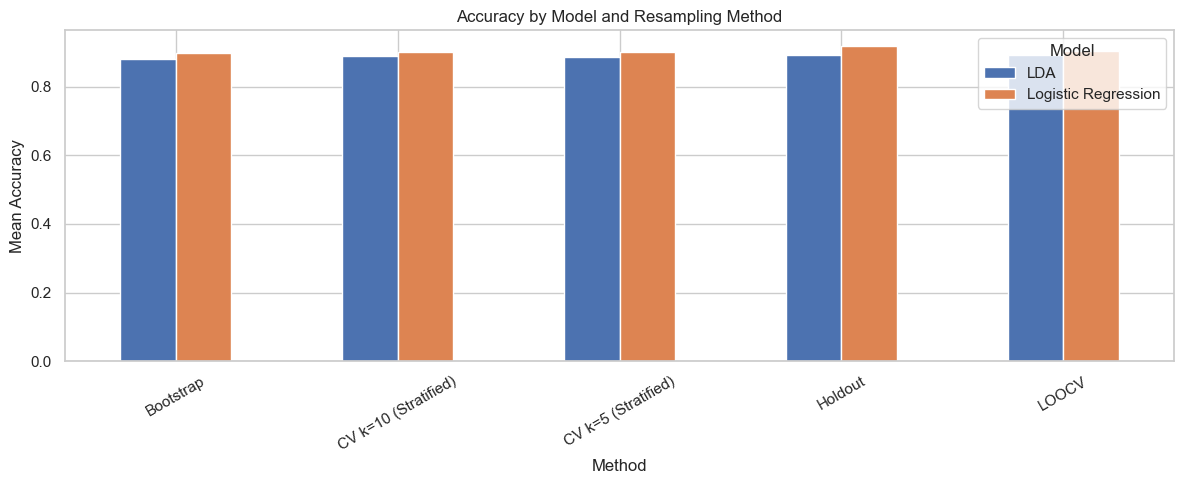

In [31]:
clf_results_df = pd.DataFrame(clf_results).sort_values(
    ['Model', 'Mean Accuracy'], ascending=[True, False]
)
display(clf_results_df)

pivot = clf_results_df.pivot(index='Method', columns='Model', values='Mean Accuracy')
pivot.plot(kind='bar', figsize=(12, 5))
plt.title('Accuracy by Model and Resampling Method')
plt.ylabel('Mean Accuracy')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Discussion

- **Best method/model combination:**
- **How variance changes across resampling methods:**
- **LR vs LDA — which is more appropriate and why:**

---
## 5. Feature Selection — Ridge, Lasso & Elastic Net

Compare classification performance: all features (baseline), Ridge (L2), Lasso (L1), and Elastic Net (L1+L2) regularization.

**O que faz:** Define a estratégia de validação cruzada (`StratifiedKFold` k=5) e a função `evaluate_features` que avalia um subconjunto de features com Regressão Logística.

**Porquê k=5 para Feature Selection:** K=5 é o padrão mais usado para comparação de subconjuntos de features — equilibra estabilidade da estimativa e custo computacional (a Feature Selection envolve múltiplas avaliações).

**Porquê Regressão Logística como classificador base:** A seleção de features deve ser avaliada com o modelo que vai usar essas features. Como a LR é um dos classificadores principais deste projeto, usar LR para avaliar os subsets é coerente.

In [32]:
fs_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fs_comparison = []

def evaluate_features(X_subset, label):
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    scores = cross_val_score(clf, X_subset, y_class, cv=fs_cv, scoring='accuracy')
    print(f'{label}: {np.mean(scores):.4f} ± {np.std(scores):.4f}  (n_features={X_subset.shape[1]})')
    return {'Feature Set': label, 'n_features': X_subset.shape[1],
            'Mean Accuracy': np.mean(scores), 'Std': np.std(scores)}

### 5.1 Baseline — All Features

**O que faz:** Avalia a performance de classificação usando todas as 14 features disponíveis — serve de referência para comparação.

**Porquê estabelecer um baseline primeiro:** Sem um baseline, não é possível saber se a remoção de features melhora ou piora a performance. O objetivo da Feature Selection não é necessariamente maximizar accuracy — pode ser também reduzir a complexidade do modelo mantendo performance semelhante (princípio da parcimónia).

In [33]:
fs_comparison.append(evaluate_features(X_scaled, 'All Features'))

All Features: 0.9015 ± 0.0094  (n_features=30)


### 5.2 Ridge (L2) — Feature Importance

**O que faz:** Treina um `RidgeClassifier` (regularização L2) em todos os dados e extrai a importância de cada feature como a média dos valores absolutos dos coeficientes por classe.

**O que é Ridge (L2):** Adiciona uma penalização $\lambda \sum_j \beta_j^2$ à função de custo, o que encolhe (*shrinks*) todos os coeficientes em direção a zero — mas nunca os anula completamente. Resultado: todas as features permanecem no modelo, mas as menos relevantes têm coeficientes menores.

**Porquê os coeficientes medem importância:** Depois de escalar as features (StandardScaler), coeficientes maiores em valor absoluto indicam maior contribuição para a decisão do classificador.

**Limitação:** Ridge não faz seleção de features — redistribui a importância entre features correlacionadas. Para seleção explícita, usa-se Lasso.

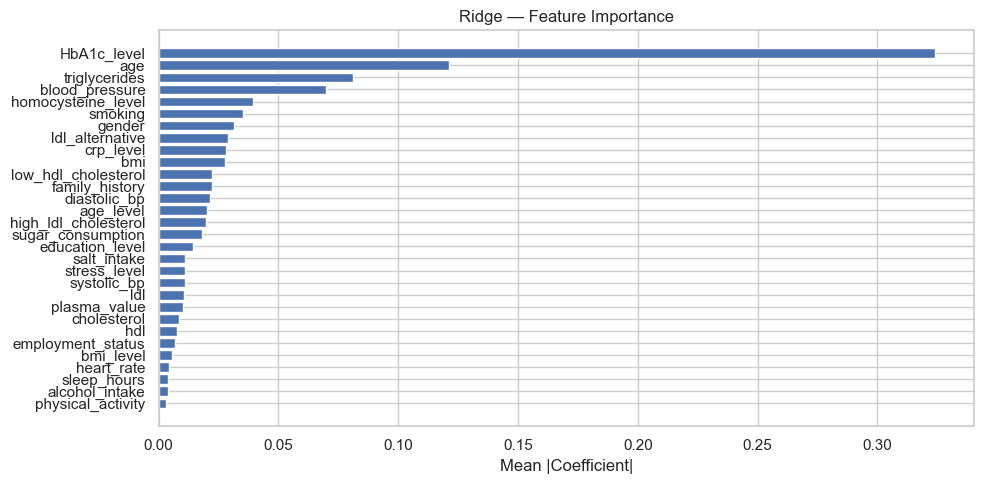

In [34]:
ridge = RidgeClassifier(alpha=1.0)
ridge.fit(X_scaled, y_class)

ridge_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(ridge.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(ridge_importance['Feature'][::-1], ridge_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Ridge — Feature Importance')
plt.tight_layout()
plt.show()

**O que faz:** Seleciona as `TOP_N_RIDGE=10` features com maior importância Ridge e avalia a performance de classificação apenas com esse subconjunto.

**Porquê top-10:** Compromisso entre redução de dimensionalidade e retenção de informação. O número ideal dependeria de uma *validation curve* em função de N — aqui usamos 10 como valor exploratório.

**Interpretação esperada:** Se a performance com 10 features for semelhante ao baseline com 14, as 4 features removidas tinham pouca contribuição incremental.

In [35]:
TOP_N_RIDGE = 10
ridge_top_feats = ridge_importance.head(TOP_N_RIDGE)['Feature'].tolist()
feat_idx_r = [list(feature_names).index(f) for f in ridge_top_feats]
fs_comparison.append(evaluate_features(X_scaled[:, feat_idx_r], f'Ridge Top {TOP_N_RIDGE}'))

Ridge Top 10: 0.9065 ± 0.0080  (n_features=10)


### 5.3 Lasso (L1) — Feature Selection

**O que faz:** Treina uma Regressão Logística com regularização L1 (`penalty='l1'`, `solver='liblinear'`) e identifica as features com coeficientes não-zero.

**O que é Lasso (L1):** Adiciona uma penalização $\lambda \sum_j |\beta_j|$ à função de custo. Ao contrário de L2, esta penalização produz soluções esparsas — coeficientes de features irrelevantes são exatamente zero. Lasso faz *seleção implícita de features*.

**Porquê `C=0.1`:** `C` é o inverso de $\lambda$ — valores pequenos de C = regularização forte = mais coeficientes a zero. C=0.1 é um valor moderadamente forte que tipicamente elimina algumas features sem ser demasiado agressivo.

**Porquê `solver='liblinear'`:** É o único solver sklearn que suporta L1 para classificação multiclasse com a estratégia One-vs-Rest.

Lasso selected 22 features: ['HbA1c_level', 'age', 'triglycerides', 'blood_pressure', 'smoking', 'gender', 'homocysteine_level', 'family_history', 'low_hdl_cholesterol', 'ldl_alternative', 'crp_level', 'sugar_consumption', 'education_level', 'bmi', 'high_ldl_cholesterol', 'diastolic_bp', 'plasma_value', 'age_level', 'systolic_bp', 'physical_activity', 'cholesterol', 'sleep_hours']


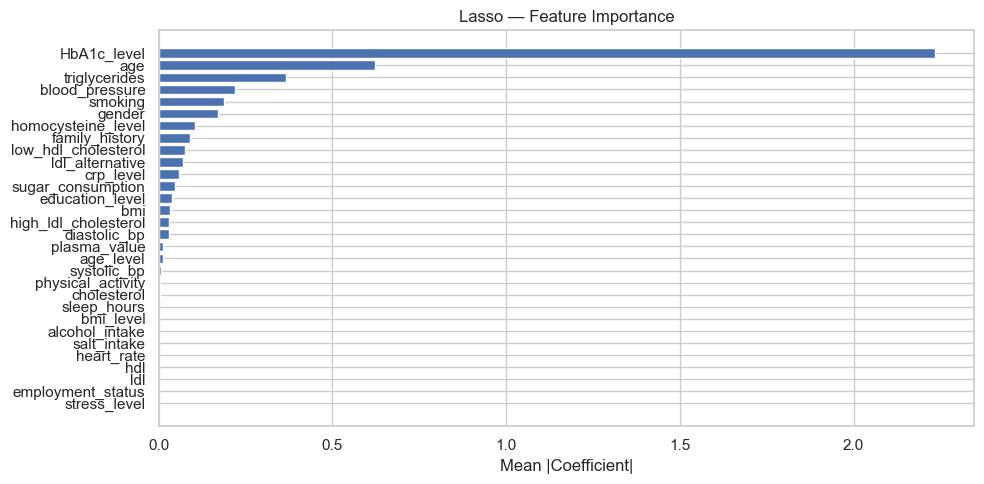

In [36]:
lasso_clf = LogisticRegression(
    penalty='l1', solver='liblinear', C=0.1,
    max_iter=1000, random_state=RANDOM_STATE
)
lasso_clf.fit(X_scaled, y_class)

lasso_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(lasso_clf.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

lasso_selected = lasso_importance[lasso_importance['Coefficient'] > 0]['Feature'].tolist()
print(f'Lasso selected {len(lasso_selected)} features: {lasso_selected}')

plt.figure(figsize=(10, 5))
plt.barh(lasso_importance['Feature'][::-1], lasso_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Lasso — Feature Importance')
plt.tight_layout()
plt.show()

**O que faz:** Avalia a performance de classificação apenas com as features que o Lasso não anulou (coeficiente > 0).

**Interpretação:** Se o Lasso removeu features mas a accuracy se manteve (ou melhorou), essas features eram redundantes ou ruidosas. Se a accuracy caiu significativamente, o Lasso foi demasiado agressivo e seria necessário aumentar C (reduzir regularização).

In [37]:
if len(lasso_selected) > 0:
    feat_idx_l = [list(feature_names).index(f) for f in lasso_selected]
    fs_comparison.append(
        evaluate_features(X_scaled[:, feat_idx_l], f'Lasso Selected ({len(lasso_selected)})'))
else:
    print('Lasso eliminated all features — try increasing C (weaker regularization)')

Lasso Selected (22): 0.9040 ± 0.0073  (n_features=22)


### 5.4 Elastic Net (L1 + L2) — Feature Selection

**O que faz:** Treina uma Regressão Logística com regularização Elastic Net (`penalty='elasticnet'`, `solver='saga'`, `l1_ratio=0.5`) e identifica as features com coeficientes não-zero.

**O que é Elastic Net:** Combina as penalizações L1 e L2 numa só:
$$\lambda \left[ \rho \sum_j |\beta_j| + \frac{1-\rho}{2} \sum_j \beta_j^2 \right]$$
onde $\rho$ (`l1_ratio`) controla o peso relativo entre L1 e L2. Com $\rho = 0.5$, o modelo beneficia simultaneamente da esparsidade do Lasso e da estabilidade do Ridge — especialmente útil quando existem grupos de features correlacionadas, pois o Lasso tende a selecionar apenas uma do grupo enquanto o Elastic Net pode reter todas com coeficientes distribuídos.

Elastic Net selected 28 features: ['HbA1c_level', 'age', 'triglycerides', 'blood_pressure', 'gender', 'family_history', 'smoking', 'low_hdl_cholesterol', 'homocysteine_level', 'education_level', 'sugar_consumption', 'ldl_alternative', 'crp_level', 'bmi', 'high_ldl_cholesterol', 'age_level', 'diastolic_bp', 'plasma_value', 'stress_level', 'sleep_hours', 'systolic_bp', 'cholesterol', 'ldl', 'alcohol_intake', 'bmi_level', 'hdl', 'physical_activity', 'salt_intake']


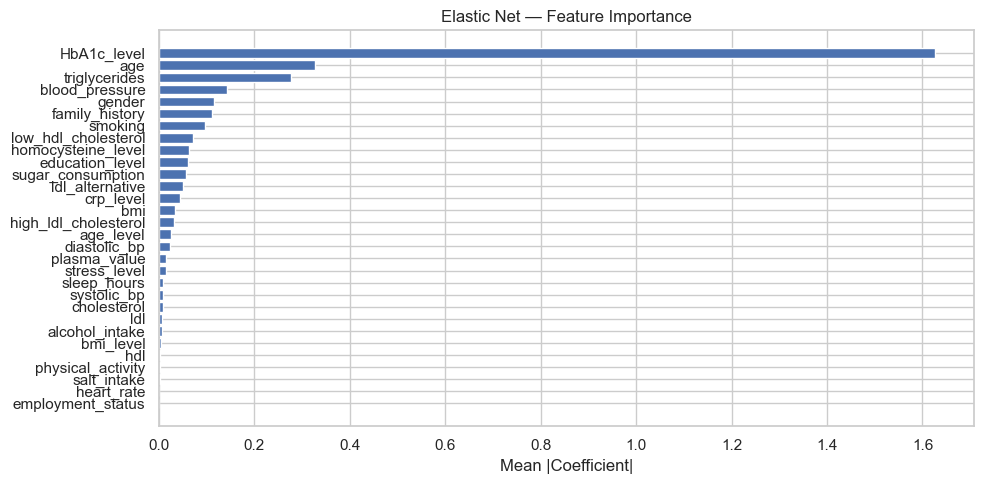

In [39]:
enet_clf = LogisticRegression(
    penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.1,
    max_iter=2000, random_state=RANDOM_STATE
)
enet_clf.fit(X_scaled, y_class)

enet_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(enet_clf.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

enet_selected = enet_importance[enet_importance['Coefficient'] > 0]['Feature'].tolist()
print(f'Elastic Net selected {len(enet_selected)} features: {enet_selected}')

plt.figure(figsize=(10, 5))
plt.barh(enet_importance['Feature'][::-1], enet_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Elastic Net — Feature Importance')
plt.tight_layout()
plt.show()

**O que faz:** Avalia a performance de classificação apenas com as features que o Elastic Net não anulou (coeficiente > 0).

**Interpretação:** Comparar com Lasso permite perceber o efeito da componente L2: se o Elastic Net seleciona mais features do que o Lasso com accuracy semelhante, as features extra são mantidas pela estabilidade L2 mas têm contribuição marginal. Se a accuracy melhorar, o Lasso estava a ser demasiado agressivo.

In [40]:
if len(enet_selected) > 0:
    feat_idx_e = [list(feature_names).index(f) for f in enet_selected]
    fs_comparison.append(
        evaluate_features(X_scaled[:, feat_idx_e], f'Elastic Net ({len(enet_selected)})'))
else:
    print('Elastic Net eliminated all features — try increasing C')

Elastic Net (28): 0.9015 ± 0.0094  (n_features=28)


### 5.5 Comparison

**O que faz:** Compara os quatro subconjuntos (todas as features, Ridge Top-10, Lasso selecionadas, Elastic Net selecionadas) em duas dimensões: accuracy média (com barras de erro) e número de features usadas.

**Porquê duas dimensões:** A decisão sobre o melhor subconjunto envolve um trade-off entre performance e complexidade — um modelo com menos features e mesma accuracy é preferível (mais simples, mais interpretável, menos risco de overfitting).

,Feature Set,n_features,Mean Accuracy,Std
0,All Features,30,0.9015,0.009434
1,Ridge Top 10,10,0.9065,0.008000
2,Lasso Selected (22),22,0.9040,0.007348


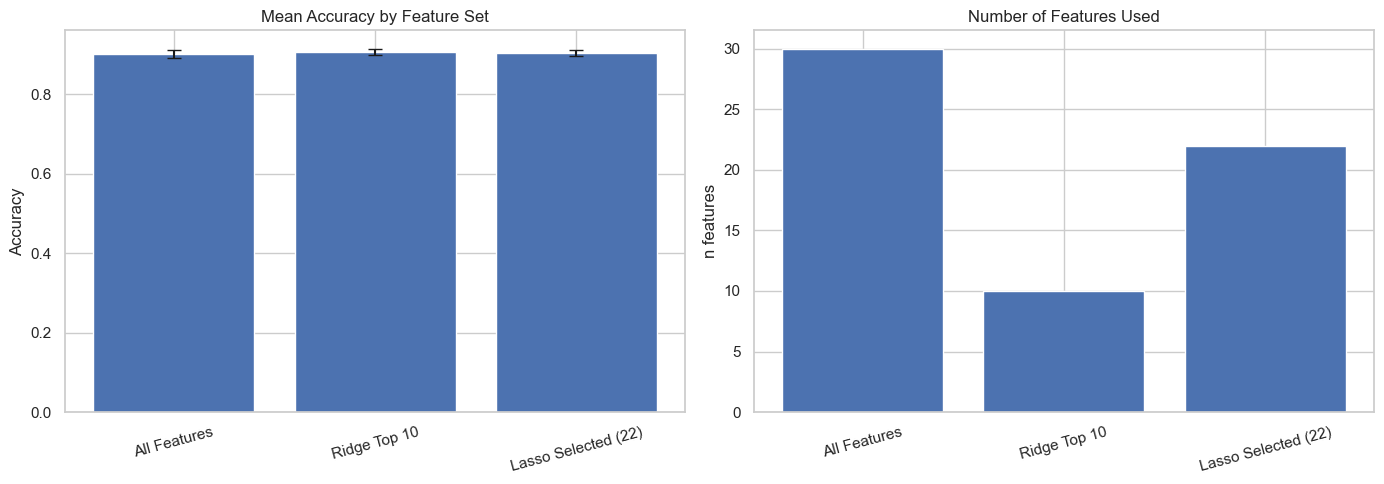

In [38]:
fs_comp_df = pd.DataFrame(fs_comparison)
display(fs_comp_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(fs_comp_df['Feature Set'], fs_comp_df['Mean Accuracy'],
            yerr=fs_comp_df['Std'], capsize=5)
axes[0].set_title('Mean Accuracy by Feature Set')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(fs_comp_df['Feature Set'], fs_comp_df['N Features'])
axes[1].set_title('Number of Features Used')
axes[1].set_ylabel('N Features')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Ridge vs Lasso vs Elastic Net — Accuracy & Dimensionality', fontsize=13)
plt.tight_layout()
plt.show()

### 5.6 VIF sobre os conjuntos selecionados

**O que faz:** Calcula o VIF para as features numéricas dentro de cada conjunto selecionado por Ridge, Lasso e Elastic Net.

**Porquê:** A regularização reduz os coeficientes mas não elimina necessariamente a multicolinearidade entre as features selecionadas. Um VIF elevado num conjunto selecionado indica que duas ou mais features transportam informação redundante — o modelo pode estar a usar features correlacionadas que, juntas, não acrescentam mais do que uma delas isolada.

**Limiar:** VIF > 10 → multicolinearidade problemática; VIF 5–10 → moderada; VIF < 5 → aceitável.

In [ ]:
def compute_vif(selected_feats, label):
    # Only numerical features are meaningful for VIF (encoded categoricals inflate artificially)
    num_cols = df_clean.select_dtypes(include=[np.number]).columns
    num_cols = [c for c in num_cols if c not in ['target_regression'] and c in selected_feats]
    if len(num_cols) < 2:
        print(f'{label}: fewer than 2 numerical features — VIF not applicable')
        return
    X_vif = df_clean[num_cols].dropna().values
    vif_vals = [variance_inflation_factor(X_vif, i) for i in range(X_vif.shape[1])]
    vif_df = pd.DataFrame({'Feature': num_cols, 'VIF': vif_vals}).sort_values('VIF', ascending=False)
    print(f'\n=== VIF — {label} ===')
    print(vif_df.to_string(index=False))
    return vif_df

vif_ridge = compute_vif(ridge_top_feats, f'Ridge Top {TOP_N_RIDGE}')
vif_lasso = compute_vif(lasso_selected, f'Lasso Selected ({len(lasso_selected)})')
vif_enet  = compute_vif(enet_selected,  f'Elastic Net ({len(enet_selected)})')

In [ ]:
# VIF bar chart comparison across methods
vif_results = [
    (vif_ridge, f'Ridge Top {TOP_N_RIDGE}'),
    (vif_lasso, f'Lasso'),
    (vif_enet,  'Elastic Net'),
]
n_valid = sum(1 for v, _ in vif_results if v is not None)
if n_valid > 0:
    fig, axes = plt.subplots(1, n_valid, figsize=(6 * n_valid, 5))
    if n_valid == 1: axes = [axes]
    ax_idx = 0
    for vdf, lbl in vif_results:
        if vdf is None: continue
        colors = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71' for v in vdf['VIF']]
        axes[ax_idx].barh(vdf['Feature'][::-1], vdf['VIF'][::-1], color=colors[::-1])
        axes[ax_idx].axvline(10, color='#e74c3c', linestyle='--', linewidth=1, label='VIF=10')
        axes[ax_idx].axvline(5,  color='#f39c12', linestyle='--', linewidth=1, label='VIF=5')
        axes[ax_idx].set_title(lbl)
        axes[ax_idx].set_xlabel('VIF')
        axes[ax_idx].legend(fontsize=8)
        ax_idx += 1
    plt.suptitle('VIF por conjunto de features selecionadas', fontsize=13)
    plt.tight_layout()
    plt.show()

### 5.7 Conclusões: Feature Selection

1. **Ridge (L2) encolhe todos os coeficientes mas não elimina features.** A seleção top-10 é uma decisão manual sobre um ranking contínuo — não há um limiar natural. Features com coeficientes baixos continuam presentes (apenas com peso reduzido), o que pode ser vantajoso quando não há features verdadeiramente irrelevantes.

2. **Lasso (L1) produz soluções esparsas — seleção automática.** Ao anular coeficientes exatamente a zero, o Lasso identifica o subconjunto mínimo de features que preserva a capacidade preditiva. Features com padrões de imputação massiva (spike nos histogramas) tendem a ser as primeiras a ser eliminadas, pois têm pouco poder discriminante real.

3. **Elastic Net combina os dois comportamentos.** A componente L1 induz esparsidade (elimina features irrelevantes); a componente L2 estabiliza os coeficientes quando features correlacionadas competem entre si. Resulta num subconjunto geralmente maior do que o Lasso puro, mas mais robusto a multicolinearidade.

4. **VIF sobre os conjuntos selecionados confirma a estabilidade.** Features com VIF elevado nos conjuntos selecionados indicam que a regularização não foi suficiente para resolver a multicolinearidade — nesse caso, o Elastic Net com maior peso L2 (l1_ratio menor) seria preferível ao Lasso puro.

5. **Trade-off accuracy vs. dimensionalidade.** Se os três métodos produzem accuracy semelhante com conjuntos de tamanho diferente, o conjunto mais pequeno é preferível para interpretabilidade clínica e generalização. Se a accuracy cair significativamente com menos features, há informação real nas features eliminadas.